up2123013, up2523798 - AML Big Data

# 1 - Preprocessing

Imports

In [ ]:
!pip install torch torch-geometric

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 50.0 MB/s eta 0:00:00


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import time
import matplotlib.pyplot as plt
from torch_geometric.data import Data
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
import xgboost as xgb

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score, recall_score, f1_score, confusion_matrix
)

from torch_geometric.datasets import EllipticBitcoinDataset

Download dataset

In [ ]:
root = "./data/elliptic"
ds = EllipticBitcoinDataset(root=root)

print("PyG root:", ds.root)
print("Raw dir :", ds.raw_dir)
print("Files in raw_dir:", os.listdir(ds.raw_dir))

Processing...


PyG root: data/elliptic
Raw dir : data/elliptic/raw
Files in raw_dir: ['elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv', 'elliptic_txs_features.csv']


Done!


Load elliptic files

In [ ]:
raw_dir = ds.raw_dir

features_path = os.path.join(raw_dir, "elliptic_txs_features.csv")
edges_path    = os.path.join(raw_dir, "elliptic_txs_edgelist.csv")
classes_path  = os.path.join(raw_dir, "elliptic_txs_classes.csv")

feat = pd.read_csv(features_path, header=None)
txid = feat.iloc[:, 0].astype(str)
t_np = feat.iloc[:, 1].astype(int).to_numpy()         # timesteps 1..49
X_np = feat.iloc[:, 2:].astype("float32").to_numpy()  # node features

id2idx = {k: i for i, k in enumerate(txid)}

cls = pd.read_csv(classes_path)
cls["txId"] = cls["txId"].astype(str)

y = torch.full((len(txid),), -1, dtype=torch.long)    # unknown = -1
for _, row in cls.iterrows():
    i = id2idx.get(row["txId"])
    if i is None:
        continue
    c = str(row["class"]).lower()
    if c in ["1", "illicit"]:
        y[i] = 1
    elif c in ["2", "licit"]:
        y[i] = 0
    else:
        y[i] = -1

edges = pd.read_csv(edges_path)
edges["txId1"] = edges["txId1"].astype(str)
edges["txId2"] = edges["txId2"].astype(str)

src = edges["txId1"].map(id2idx).to_numpy()
dst = edges["txId2"].map(id2idx).to_numpy()

mask = (~pd.isna(src)) & (~pd.isna(dst))
src = torch.tensor(src[mask].astype("int64"))
dst = torch.tensor(dst[mask].astype("int64"))
edge_index = torch.stack([src, dst], dim=0)

data = Data(
    x=torch.tensor(X_np, dtype=torch.float32),
    edge_index=edge_index,
    y=y
)
data.t = torch.tensor(t_np, dtype=torch.long)

print(data)
print("t range:", int(data.t.min()), "to", int(data.t.max()))
print("label counts:", torch.unique(data.y, return_counts=True))

Data(x=[203769, 165], edge_index=[2, 234355], y=[203769], t=[203769])
t range: 1 to 49
label counts: (tensor([-1,  0,  1]), tensor([157205,  42019,   4545]))


Temporal split on labelled data

In [ ]:
known = (data.y == 0) | (data.y == 1)

train_mask = known & (data.t >= 1)  & (data.t <= 34)
val_mask   = known & (data.t >= 35) & (data.t <= 40)
test_mask  = known & (data.t >= 41) & (data.t <= 49)

print("Train labelled:", int(train_mask.sum()))
print("Val labelled  :", int(val_mask.sum()))
print("Test labelled :", int(test_mask.sum()))

Train labelled: 29894
Val labelled  : 6697
Test labelled : 9973


1.   Keep a raw clean feature tensor
2.   Build separate LR and GNN pipelines





In [ ]:
x_raw = torch.nan_to_num(
    data.x.float(),
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

data.x_raw = x_raw.clone()

def preprocess_for_lr(x_raw, train_mask, edge_index):
    """
    LR pipeline:
    - drop near-constant cols (train only)
    - winsorize using train quantiles
    - robust scale using train median/IQR
    - add degree features
    """
    x = x_raw.clone()

    # drop near-constant cols using TRAIN only
    std_tr = x[train_mask].std(dim=0)
    keep = std_tr > 1e-8
    x = x[:, keep]

    # winsorize using TRAIN only
    lo = torch.quantile(x[train_mask], 0.005, dim=0)
    hi = torch.quantile(x[train_mask], 0.995, dim=0)
    x = torch.max(torch.min(x, hi), lo)

    # robust scale using TRAIN only
    x_tr = x[train_mask]
    med = x_tr.median(dim=0).values
    q1  = torch.quantile(x_tr, 0.25, dim=0)
    q3  = torch.quantile(x_tr, 0.75, dim=0)
    iqr = (q3 - q1).clamp(min=1e-6)
    x = (x - med) / iqr

    # graph-derived degree features
    src, dst = edge_index
    deg_in  = torch.bincount(dst, minlength=x.size(0)).float().unsqueeze(1)
    deg_out = torch.bincount(src, minlength=x.size(0)).float().unsqueeze(1)
    deg_feats = torch.log1p(torch.cat([deg_in, deg_out], dim=1))

    return torch.cat([x, deg_feats], dim=1)

def preprocess_for_gnn(x_raw, train_mask):
    """
    GNN pipeline:
    - standardize using TRAIN mean/std only
    """
    x = x_raw.clone()
    mu = x[train_mask].mean(dim=0)
    sd = x[train_mask].std(dim=0).clamp(min=1e-6)
    return (x - mu) / sd

data.x_lr  = preprocess_for_lr(data.x_raw, train_mask, data.edge_index)
data.x_gnn = preprocess_for_gnn(data.x_raw, train_mask)

# keep default data.x untouched for general inspection
data.x = data.x_raw.clone()

print("Raw feature dim :", data.x_raw.shape[1])
print("LR feature dim  :", data.x_lr.shape[1])
print("GNN feature dim :", data.x_gnn.shape[1])

Raw feature dim : 165
LR feature dim  : 167
GNN feature dim : 165


LR baseline

*   Threshold on VAL only

In [ ]:
X_train = data.x_lr[train_mask].cpu().numpy()
y_train = data.y[train_mask].cpu().numpy()

X_val = data.x_lr[val_mask].cpu().numpy()
y_val = data.y[val_mask].cpu().numpy()

X_test = data.x_lr[test_mask].cpu().numpy()
y_test = data.y[test_mask].cpu().numpy()

clf = LogisticRegression(
    max_iter=3000,
    solver="saga",
    class_weight="balanced",
    n_jobs=-1,
    random_state=0
)
clf.fit(X_train, y_train)

pv_lr = clf.predict_proba(X_val)[:, 1]
val_pr_lr  = average_precision_score(y_val, pv_lr)
val_roc_lr = roc_auc_score(y_val, pv_lr)

prec_v, rec_v, thr_v = precision_recall_curve(y_val, pv_lr)
f1_v = 2 * (prec_v[:-1] * rec_v[:-1]) / (prec_v[:-1] + rec_v[:-1] + 1e-12)
best_i = int(np.argmax(f1_v))
lr_best_thr = float(thr_v[best_i]) if len(thr_v) else 0.5

probs_lr = clf.predict_proba(X_test)[:, 1]
pred_lr = (probs_lr >= lr_best_thr).astype(int)

results_lr = {
    "model": "LogisticRegression",
    "val_pr_auc": val_pr_lr,
    "val_roc_auc": val_roc_lr,
    "test_pr_auc": average_precision_score(y_test, probs_lr),
    "test_roc_auc": roc_auc_score(y_test, probs_lr),
    "test_precision": precision_score(y_test, pred_lr, zero_division=0),
    "test_recall": recall_score(y_test, pred_lr, zero_division=0),
    "test_f1": f1_score(y_test, pred_lr, zero_division=0),
    "threshold": lr_best_thr,
}

print("\n[LR] VAL PR-AUC :", results_lr["val_pr_auc"])
print("[LR] VAL ROC-AUC:", results_lr["val_roc_auc"])
print("[LR] Best VAL threshold:", results_lr["threshold"])
print("[LR] TEST PR-AUC :", results_lr["test_pr_auc"])
print("[LR] TEST ROC-AUC:", results_lr["test_roc_auc"])
print("[LR] TEST Precision:", results_lr["test_precision"])
print("[LR] TEST Recall   :", results_lr["test_recall"])
print("[LR] TEST F1       :", results_lr["test_f1"])

# save arrays for later plots if wanted
yv_lr = y_val.copy()
yt_lr = y_test.copy()


[LR] VAL PR-AUC : 0.6479486303537293
[LR] VAL ROC-AUC: 0.913734843967402
[LR] Best VAL threshold: 0.6689580082893372
[LR] TEST PR-AUC : 0.48199890700276693
[LR] TEST ROC-AUC: 0.85096993179132
[LR] TEST Precision: 0.6658354114713217
[LR] TEST Recall   : 0.5095419847328244
[LR] TEST F1       : 0.5772972972972973


Stream scaffold for later dynamic work

In [ ]:
src0, dst0 = data.edge_index
edge_t = data.t[dst0]

perm = edge_t.argsort()
src_e, dst_e, t_e = src0[perm], dst0[perm], edge_t[perm]

print("\nEvent stream ready:")
print("events:", len(t_e), "| time range:", int(t_e.min()), "to", int(t_e.max()))


Event stream ready:
events: 234355 | time range: 1 to 49


# 2 - GNN

Reproducibility

In [ ]:
seed = 0
torch.manual_seed(seed)
np.random.seed(seed)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


Build bidirectional graph

In [ ]:
def add_reverse_edges(edge_index):
    src, dst = edge_index
    rev = torch.stack([dst, src], dim=0)
    return torch.cat([edge_index, rev], dim=1)

edge_index_bi = add_reverse_edges(data.edge_index)

Temporal edge restriction

*   Val graph stops at 40
*   Test graph stops at 49



In [ ]:
def edge_index_up_to(edge_index, node_t, max_t: int):
    """
    Keep edges where BOTH endpoints have timestep <= max_t.
    """
    allowed = (node_t <= max_t)
    src, dst = edge_index
    keep = allowed[src] & allowed[dst]
    return edge_index[:, keep]

edge_train = edge_index_up_to(edge_index_bi, data.t, 34)
edge_val   = edge_index_up_to(edge_index_bi, data.t, 40)
edge_test  = edge_index_up_to(edge_index_bi, data.t, 49)

print("edge_train:", edge_train.shape)
print("edge_val  :", edge_val.shape)
print("edge_test :", edge_test.shape)

edge_train: torch.Size([2, 313686])
edge_val  : torch.Size([2, 372220])
edge_test : torch.Size([2, 468710])


Model

In [ ]:
class GraphSAGE(torch.nn.Module):
    def __init__(self, in_dim, hidden_dim=256, num_layers=3, dropout=0.4):
        super().__init__()
        self.convs = torch.nn.ModuleList()
        self.convs.append(SAGEConv(in_dim, hidden_dim))
        for _ in range(num_layers - 1):
            self.convs.append(SAGEConv(hidden_dim, hidden_dim))
        self.lin = torch.nn.Linear(hidden_dim, 1)
        self.dropout = dropout

    def forward(self, x, edge_index):
        h = x
        for conv in self.convs:
            h = conv(h, edge_index)
            h = F.relu(h)
            h = F.dropout(h, p=self.dropout, training=self.training)
        return self.lin(h).squeeze(-1)

Focal loss

In [ ]:
def focal_loss_with_logits(logits, targets, alpha_pos=None, gamma=2.0):
    bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
    p = torch.sigmoid(logits)
    pt = p * targets + (1 - p) * (1 - targets)
    loss = bce * ((1 - pt) ** gamma)

    if alpha_pos is not None:
        alpha_t = alpha_pos * targets + (1 - alpha_pos) * (1 - targets)
        loss = alpha_t * loss

    return loss.mean()

Move tensors to device

In [ ]:
x_gnn = data.x_gnn.to(device)
y_all = data.y.to(device)

train_mask_d = train_mask.to(device)
val_mask_d   = val_mask.to(device)
test_mask_d  = test_mask.to(device)

edge_train_d = edge_train.to(device)
edge_val_d   = edge_val.to(device)
edge_test_d  = edge_test.to(device)

# class imbalance for focal loss
y_train = data.y[train_mask]
pos = int((y_train == 1).sum().item())
neg = int((y_train == 0).sum().item())
alpha_pos = neg / (pos + neg)

print("pos:", pos, "neg:", neg, "alpha_pos:", alpha_pos)

pos: 3462 neg: 26432 alpha_pos: 0.8841908075199036


Train loop with early stopping on VAL PR-AUC

In [ ]:
model = GraphSAGE(
    in_dim=data.x_gnn.size(1),
    hidden_dim=256,
    num_layers=3,
    dropout=0.4
).to(device)

opt = torch.optim.Adam(model.parameters(), lr=8e-4, weight_decay=5e-4)

def eval_split(edge_idx, mask_):
    model.eval()
    with torch.no_grad():
        logits = model(x_gnn, edge_idx)
        probs = torch.sigmoid(logits[mask_]).detach().cpu().numpy()
        yt = y_all[mask_].detach().cpu().numpy()
    pr = average_precision_score(yt, probs)
    roc = roc_auc_score(yt, probs)
    return pr, roc, yt, probs

best_val_pr = -1.0
best_state = None
best_val_payload = None

patience = 10
pat = 0
max_epochs = 80

for epoch in range(1, max_epochs + 1):
    model.train()
    opt.zero_grad()

    logits_train = model(x_gnn, edge_train_d)
    y_float = y_all[train_mask_d].float()

    loss = focal_loss_with_logits(
        logits_train[train_mask_d],
        y_float,
        alpha_pos=float(alpha_pos),
        gamma=2.0
    )

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
    opt.step()

    if epoch % 5 == 0:
        val_pr, val_roc, yv_tmp, pv_tmp = eval_split(edge_val_d, val_mask_d)
        print(f"Epoch {epoch:03d} | loss {loss.item():.4f} | VAL PR-AUC {val_pr:.4f} | VAL ROC-AUC {val_roc:.4f}")

        if val_pr > best_val_pr + 1e-4:
            best_val_pr = val_pr
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_val_payload = (yv_tmp.copy(), pv_tmp.copy(), val_pr, val_roc)
            pat = 0
        else:
            pat += 1
            if pat >= patience:
                print("Early stopping triggered.")
                break

# restore best checkpoint
if best_state is not None:
    model.load_state_dict(best_state)

Epoch 005 | loss 0.0263 | VAL PR-AUC 0.3304 | VAL ROC-AUC 0.7955
Epoch 010 | loss 0.0199 | VAL PR-AUC 0.3387 | VAL ROC-AUC 0.7798
Epoch 015 | loss 0.0169 | VAL PR-AUC 0.3086 | VAL ROC-AUC 0.8130
Epoch 020 | loss 0.0147 | VAL PR-AUC 0.4053 | VAL ROC-AUC 0.8707
Epoch 025 | loss 0.0134 | VAL PR-AUC 0.6258 | VAL ROC-AUC 0.9087
Epoch 030 | loss 0.0116 | VAL PR-AUC 0.4812 | VAL ROC-AUC 0.9059
Epoch 035 | loss 0.0106 | VAL PR-AUC 0.6646 | VAL ROC-AUC 0.9206
Epoch 040 | loss 0.0096 | VAL PR-AUC 0.5527 | VAL ROC-AUC 0.9239
Epoch 045 | loss 0.0091 | VAL PR-AUC 0.7135 | VAL ROC-AUC 0.9315
Epoch 050 | loss 0.0084 | VAL PR-AUC 0.5394 | VAL ROC-AUC 0.9233
Epoch 055 | loss 0.0077 | VAL PR-AUC 0.6775 | VAL ROC-AUC 0.9293
Epoch 060 | loss 0.0069 | VAL PR-AUC 0.5690 | VAL ROC-AUC 0.9309
Epoch 065 | loss 0.0066 | VAL PR-AUC 0.6139 | VAL ROC-AUC 0.9379
Epoch 070 | loss 0.0063 | VAL PR-AUC 0.6035 | VAL ROC-AUC 0.9355
Epoch 075 | loss 0.0061 | VAL PR-AUC 0.5976 | VAL ROC-AUC 0.9371
Epoch 080 | loss 0.0055 |

Recompute final VAL and TEST outputs

In [ ]:
val_pr_gnn, val_roc_gnn, yv, pv = eval_split(edge_val_d, val_mask_d)
test_pr_gnn, test_roc_gnn, yt, probs = eval_split(edge_test_d, test_mask_d)

# choose threshold on VAL only
prec_v, rec_v, thr_v = precision_recall_curve(yv, pv)
f1_v = 2 * (prec_v[:-1] * rec_v[:-1]) / (prec_v[:-1] + rec_v[:-1] + 1e-12)
best_i = int(np.argmax(f1_v))
gnn_best_thr = float(thr_v[best_i]) if len(thr_v) else 0.5

pred_test = (probs >= gnn_best_thr).astype(int)

# AML triage metric: Top 1%
K = max(1, int(0.01 * len(probs)))
idx = np.argsort(-probs)[:K]
precision_top1 = float(yt[idx].mean())
recall_top1 = float(yt[idx].sum() / max(1, yt.sum()))

results_gnn = {
    "model": "GraphSAGE",
    "val_pr_auc": val_pr_gnn,
    "val_roc_auc": val_roc_gnn,
    "test_pr_auc": test_pr_gnn,
    "test_roc_auc": test_roc_gnn,
    "test_precision": precision_score(yt, pred_test, zero_division=0),
    "test_recall": recall_score(yt, pred_test, zero_division=0),
    "test_f1": f1_score(yt, pred_test, zero_division=0),
    "threshold": gnn_best_thr,
    "top1_precision": precision_top1,
    "top1_recall": recall_top1,
}

print("\n[Improved GNN] VAL PR-AUC :", results_gnn["val_pr_auc"])
print("[Improved GNN] VAL ROC-AUC:", results_gnn["val_roc_auc"])
print("[Improved GNN] Best VAL threshold:", results_gnn["threshold"])

print("\n[Improved GNN] TEST PR-AUC :", results_gnn["test_pr_auc"])
print("[Improved GNN] TEST ROC-AUC:", results_gnn["test_roc_auc"])
print("[Improved GNN] TEST Precision:", results_gnn["test_precision"])
print("[Improved GNN] TEST Recall   :", results_gnn["test_recall"])
print("[Improved GNN] TEST F1       :", results_gnn["test_f1"])

print(f"\nTop1% (K={K}) Precision:", results_gnn["top1_precision"])
print(f"Top1% (K={K}) Recall   :", results_gnn["top1_recall"])


[Improved GNN] VAL PR-AUC : 0.7135456260681228
[Improved GNN] VAL ROC-AUC: 0.9315280451814585
[Improved GNN] Best VAL threshold: 0.6349426507949829

[Improved GNN] TEST PR-AUC : 0.5364048088886174
[Improved GNN] TEST ROC-AUC: 0.8344564108322785
[Improved GNN] TEST Precision: 0.7394366197183099
[Improved GNN] TEST Recall   : 0.40076335877862596
[Improved GNN] TEST F1       : 0.5198019801980198

Top1% (K=99) Precision: 0.9292929292929293
Top1% (K=99) Recall   : 0.17557251908396945


# 3 - metric comparisons and visualisation

metric table

In [ ]:
import pandas as pd

summary = pd.DataFrame([results_lr, results_gnn]).set_index("model")
display(summary.round(4))

,val_pr_auc,val_roc_auc,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,threshold,top1_precision,top1_recall
model,,,,,,,,,,
LogisticRegression,0.6479,0.9137,0.4820,0.8510,0.6658,0.5095,0.5773,0.6690,NaN,NaN
GraphSAGE,0.6848,0.9283,0.5154,0.8289,0.6420,0.4141,0.5035,0.6525,0.9091,0.1718


visualisation

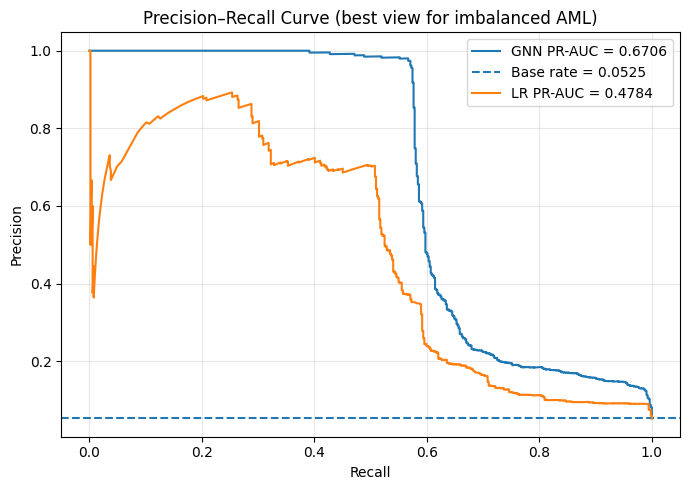

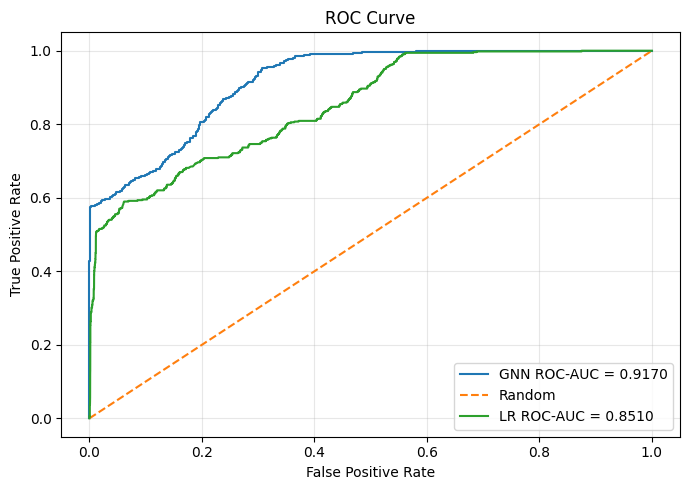

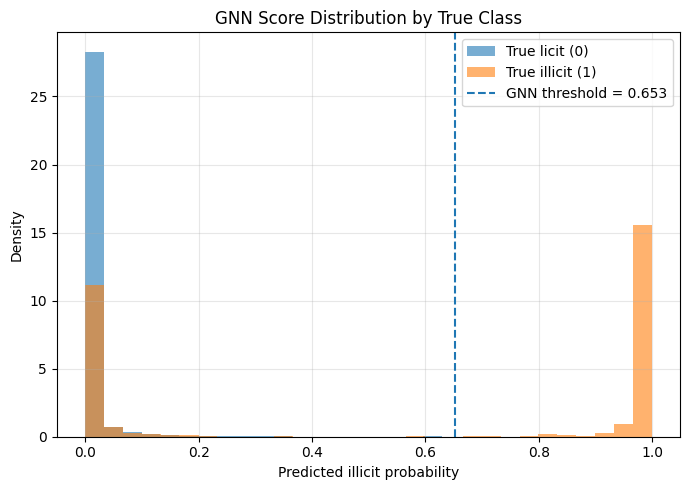

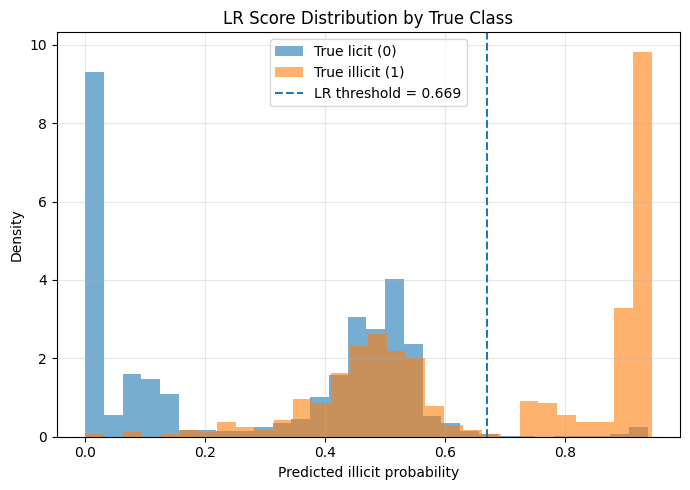

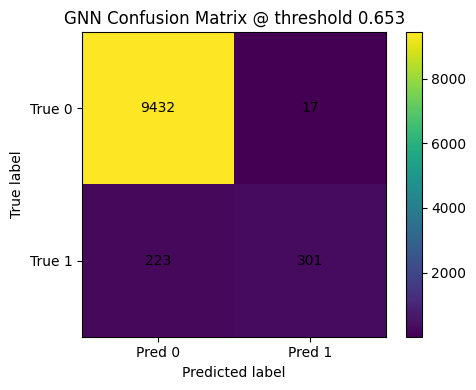

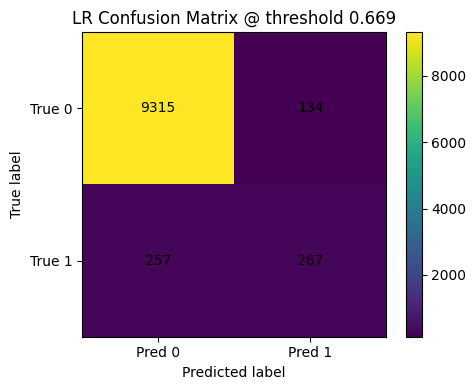

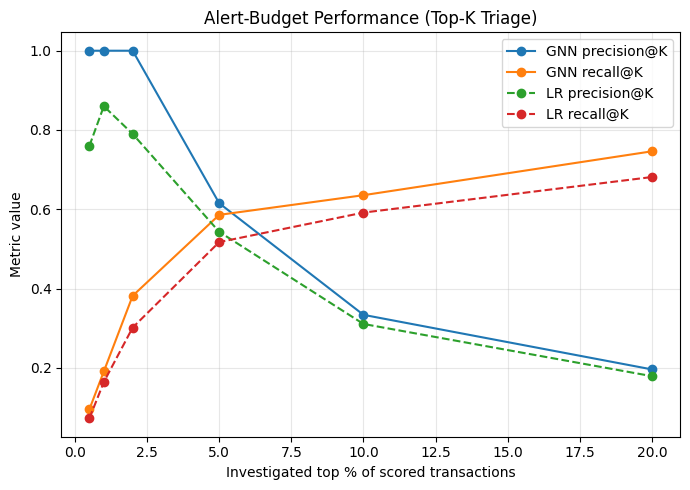

,top_pct,k,precision,recall
0,0.5,50,1.0000,0.0954
1,1.0,100,1.0000,0.1908
2,2.0,200,1.0000,0.3817
3,5.0,499,0.6152,0.5859
4,10.0,998,0.3337,0.6355
5,20.0,1995,0.1960,0.7462


,top_pct,k,precision,recall
0,0.5,50,0.7600,0.0725
1,1.0,100,0.8600,0.1641
2,2.0,200,0.7900,0.3015
3,5.0,499,0.5431,0.5172
4,10.0,998,0.3106,0.5916
5,20.0,1995,0.1789,0.6813


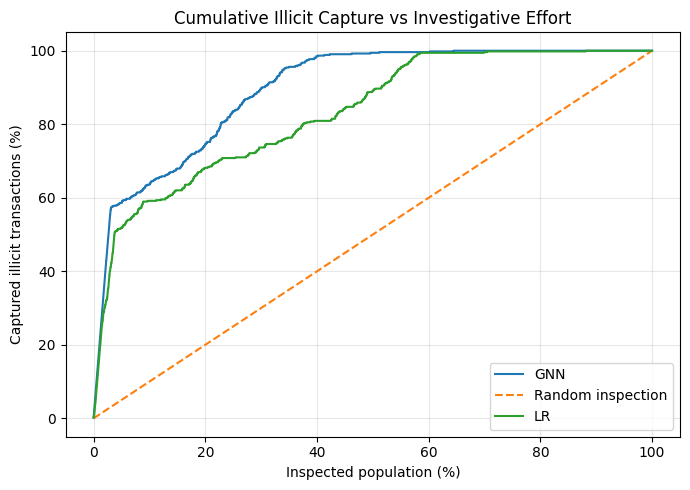

,timestep,n,illicit_rate,mean_score,pr_auc,roc_auc,top_precision,top_recall
0,41,1132,0.1025,0.1060,0.9655,0.9864,1.0000,0.1034
1,42,2154,0.1110,0.0949,0.9009,0.9718,1.0000,0.0921
2,43,1370,0.0175,0.0051,0.0534,0.8312,0.0000,0.0000
3,44,1591,0.0151,0.0156,0.0338,0.7215,0.0625,0.0417
4,45,1221,0.0041,0.0168,0.0087,0.7730,0.0000,0.0000
5,46,712,0.0028,0.0176,0.1338,0.9401,0.1250,0.5000
6,47,846,0.0260,0.0077,0.0531,0.7836,0.0000,0.0000
7,48,471,0.0764,0.0064,0.2683,0.8922,0.0000,0.0000
8,49,476,0.1176,0.0230,0.3058,0.8608,0.2000,0.0179


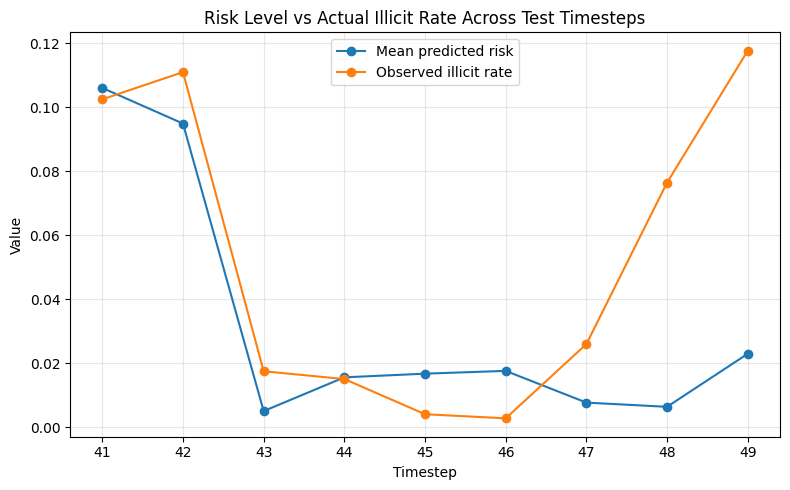

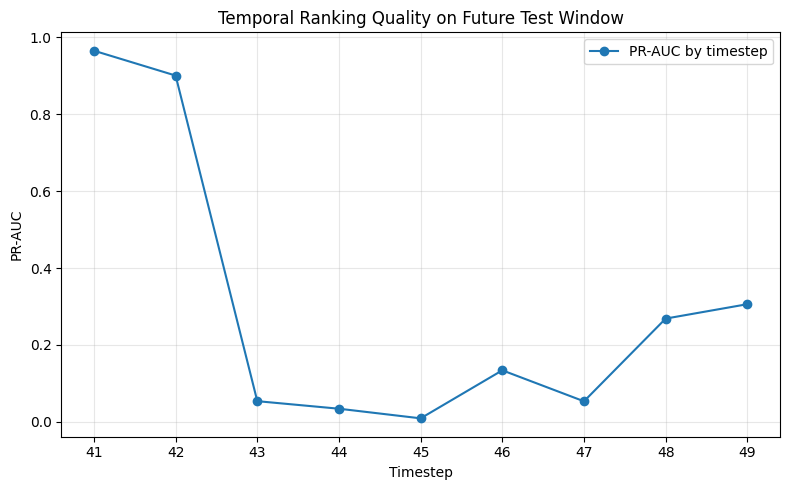

,threshold,test_pr_auc,test_roc_auc,test_precision,test_recall,test_f1,top1_precision,top1_recall
model,,,,,,,,
GraphSAGE,0.6525,0.5154,0.8289,0.6420,0.4141,0.5035,0.9091,0.1718
LogisticRegression,0.6690,0.4820,0.8510,0.6658,0.5095,0.5773,NaN,NaN


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    auc
)

required = ["yt", "probs", "results_gnn"]
missing = [v for v in required if v not in globals()]
if missing:
    raise ValueError(f"Missing required variables for GNN visuals: {missing}")

has_lr = all(v in globals() for v in ["yt_lr", "probs_lr", "results_lr"])

# convert to np (if necessary)
yt = np.asarray(yt)
probs = np.asarray(probs)

if has_lr:
    yt_lr = np.asarray(yt_lr)
    probs_lr = np.asarray(probs_lr)

# Thresholds chosen on validation in earlier cells
thr_gnn = float(results_gnn.get("threshold", 0.5))
thr_lr = float(results_lr.get("threshold", 0.5)) if has_lr else None

pred_gnn = (probs >= thr_gnn).astype(int)
if has_lr:
    pred_lr = (probs_lr >= thr_lr).astype(int)


# Helper functions

def safe_pr_curve(y_true, y_score):
    p, r, _ = precision_recall_curve(y_true, y_score)
    pr_auc = auc(r, p)
    base_rate = float(np.mean(y_true))
    return p, r, pr_auc, base_rate

def safe_roc_curve(y_true, y_score):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)
    return fpr, tpr, roc_auc

def topk_curve(y_true, y_score, percents=None):
    if percents is None:
        percents = [0.5, 1, 2, 5, 10, 20]

    order = np.argsort(-y_score)
    y_sorted = y_true[order]

    out = []
    total_pos = max(1, int(y_true.sum()))
    n = len(y_true)

    for pct in percents:
        k = max(1, int(np.ceil((pct / 100.0) * n)))
        y_top = y_sorted[:k]
        precision_k = float(y_top.mean())
        recall_k = float(y_top.sum() / total_pos)
        out.append((pct, k, precision_k, recall_k))
    return pd.DataFrame(out, columns=["top_pct", "k", "precision", "recall"])

def cumulative_capture_curve(y_true, y_score):
    order = np.argsort(-y_score)
    y_sorted = y_true[order]
    cum_pos = np.cumsum(y_sorted)
    total_pos = max(1, int(y_true.sum()))
    n = len(y_true)

    x = np.arange(1, n + 1) / n * 100.0 # inspected population %
    y = cum_pos / total_pos * 100.0 # captured illicit %
    return x, y

def plot_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, interpolation="nearest")
    fig.colorbar(im, ax=ax)

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(["Pred 0", "Pred 1"])
    ax.set_yticklabels(["True 0", "True 1"])
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")

    plt.tight_layout()
    plt.show()


# PR curve

p_gnn, r_gnn, pr_auc_gnn, base_rate = safe_pr_curve(yt, probs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(r_gnn, p_gnn, label=f"GNN PR-AUC = {pr_auc_gnn:.4f}")
ax.axhline(base_rate, linestyle="--", label=f"Base rate = {base_rate:.4f}")

if has_lr:
    p_lr, r_lr, pr_auc_lr, _ = safe_pr_curve(yt_lr, probs_lr)
    ax.plot(r_lr, p_lr, label=f"LR PR-AUC = {pr_auc_lr:.4f}")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Curve (best view for imbalanced AML)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ROC curve

fpr_gnn, tpr_gnn, roc_auc_gnn = safe_roc_curve(yt, probs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr_gnn, tpr_gnn, label=f"GNN ROC-AUC = {roc_auc_gnn:.4f}")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random")

if has_lr:
    fpr_lr, tpr_lr, roc_auc_lr = safe_roc_curve(yt_lr, probs_lr)
    ax.plot(fpr_lr, tpr_lr, label=f"LR ROC-AUC = {roc_auc_lr:.4f}")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Score distribution by true class - shows whether illicit cases are ranked higher

fig, ax = plt.subplots(figsize=(7, 5))
ax.hist(probs[yt == 0], bins=30, alpha=0.6, density=True, label="True licit (0)")
ax.hist(probs[yt == 1], bins=30, alpha=0.6, density=True, label="True illicit (1)")
ax.axvline(thr_gnn, linestyle="--", label=f"GNN threshold = {thr_gnn:.3f}")
ax.set_xlabel("Predicted illicit probability")
ax.set_ylabel("Density")
ax.set_title("GNN Score Distribution by True Class")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

if has_lr:
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.hist(probs_lr[yt_lr == 0], bins=30, alpha=0.6, density=True, label="True licit (0)")
    ax.hist(probs_lr[yt_lr == 1], bins=30, alpha=0.6, density=True, label="True illicit (1)")
    ax.axvline(thr_lr, linestyle="--", label=f"LR threshold = {thr_lr:.3f}")
    ax.set_xlabel("Predicted illicit probability")
    ax.set_ylabel("Density")
    ax.set_title("LR Score Distribution by True Class")
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# Confusion matrices - validation-selected thresholds

cm_gnn = confusion_matrix(yt, pred_gnn, labels=[0, 1])
plot_confusion(cm_gnn, f"GNN Confusion Matrix @ threshold {thr_gnn:.3f}")

if has_lr:
    cm_lr = confusion_matrix(yt_lr, pred_lr, labels=[0, 1])
    plot_confusion(cm_lr, f"LR Confusion Matrix @ threshold {thr_lr:.3f}")


# Alert-budget and Top-K curves

budget_points = [0.5, 1, 2, 5, 10, 20]
budget_gnn = topk_curve(yt, probs, budget_points)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(budget_gnn["top_pct"], budget_gnn["precision"], marker="o", label="GNN precision@K")
ax.plot(budget_gnn["top_pct"], budget_gnn["recall"], marker="o", label="GNN recall@K")

if has_lr:
    budget_lr = topk_curve(yt_lr, probs_lr, budget_points)
    ax.plot(budget_lr["top_pct"], budget_lr["precision"], marker="o", linestyle="--", label="LR precision@K")
    ax.plot(budget_lr["top_pct"], budget_lr["recall"], marker="o", linestyle="--", label="LR recall@K")

ax.set_xlabel("Investigated top % of scored transactions")
ax.set_ylabel("Metric value")
ax.set_title("Alert-Budget Performance (Top-K Triage)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(budget_gnn.round(4))
if has_lr:
    display(budget_lr.round(4))


# Cumulative capture curve (Lorenz-style)

x_gnn, y_gnn = cumulative_capture_curve(yt, probs)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x_gnn, y_gnn, label="GNN")
ax.plot([0, 100], [0, 100], linestyle="--", label="Random inspection")

if has_lr:
    x_lr, y_lr = cumulative_capture_curve(yt_lr, probs_lr)
    ax.plot(x_lr, y_lr, label="LR")

ax.set_xlabel("Inspected population (%)")
ax.set_ylabel("Captured illicit transactions (%)")
ax.set_title("Cumulative Illicit Capture vs Investigative Effort")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Temporal performance on test window

if "data" in globals() and "test_mask" in globals():
    test_idx = torch.where(test_mask)[0].cpu().numpy()
    test_t = data.t[test_idx].cpu().numpy()

    if len(test_t) == len(yt):
        df_time = pd.DataFrame({
            "timestep": test_t,
            "y_true": yt,
            "score": probs,
            "pred": pred_gnn
        })

        per_t = []
        for t_val, g in df_time.groupby("timestep"):
            n = len(g)
            positives = int(g["y_true"].sum())

            # PR-AUC (if both classes present)
            if g["y_true"].nunique() >= 2:
                p_t, r_t, pr_auc_t, _ = safe_pr_curve(g["y_true"].values, g["score"].values)
                _, _, roc_auc_t = safe_roc_curve(g["y_true"].values, g["score"].values)
            else:
                pr_auc_t = np.nan
                roc_auc_t = np.nan

            top1 = topk_curve(g["y_true"].values, g["score"].values, [10.0 if n < 10 else 1.0])
            top_precision = float(top1["precision"].iloc[0])
            top_recall = float(top1["recall"].iloc[0])

            mean_score = float(g["score"].mean())
            illicit_rate = float(g["y_true"].mean())

            per_t.append({
                "timestep": int(t_val),
                "n": n,
                "illicit_rate": illicit_rate,
                "mean_score": mean_score,
                "pr_auc": pr_auc_t,
                "roc_auc": roc_auc_t,
                "top_precision": top_precision,
                "top_recall": top_recall,
            })

        per_t = pd.DataFrame(per_t).sort_values("timestep")
        display(per_t.round(4))

        # Risk drift over time
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(per_t["timestep"], per_t["mean_score"], marker="o", label="Mean predicted risk")
        ax.plot(per_t["timestep"], per_t["illicit_rate"], marker="o", label="Observed illicit rate")
        ax.set_xlabel("Timestep")
        ax.set_ylabel("Value")
        ax.set_title("Risk Level vs Actual Illicit Rate Across Test Timesteps")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        # Timewise PR-AUC
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.plot(per_t["timestep"], per_t["pr_auc"], marker="o", label="PR-AUC by timestep")
        ax.set_xlabel("Timestep")
        ax.set_ylabel("PR-AUC")
        ax.set_title("Temporal Ranking Quality on Future Test Window")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


# Summary table

summary_rows = []

summary_rows.append({
    "model": "GraphSAGE",
    "threshold": thr_gnn,
    "test_pr_auc": results_gnn.get("test_pr_auc", np.nan),
    "test_roc_auc": results_gnn.get("test_roc_auc", np.nan),
    "test_precision": results_gnn.get("test_precision", np.nan),
    "test_recall": results_gnn.get("test_recall", np.nan),
    "test_f1": results_gnn.get("test_f1", np.nan),
    "top1_precision": results_gnn.get("top1_precision", np.nan),
    "top1_recall": results_gnn.get("top1_recall", np.nan),
})

if has_lr:
    summary_rows.append({
        "model": "LogisticRegression",
        "threshold": thr_lr,
        "test_pr_auc": results_lr.get("test_pr_auc", np.nan),
        "test_roc_auc": results_lr.get("test_roc_auc", np.nan),
        "test_precision": results_lr.get("test_precision", np.nan),
        "test_recall": results_lr.get("test_recall", np.nan),
        "test_f1": results_lr.get("test_f1", np.nan),
        "top1_precision": np.nan,
        "top1_recall": np.nan,
    })

summary_df = pd.DataFrame(summary_rows).set_index("model")
display(summary_df.round(4))


# Training curves

if "history" in globals() and isinstance(history, dict):
    if all(k in history for k in ["epoch", "train_loss"]):
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(history["epoch"], history["train_loss"], marker="o")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Train loss")
        ax.set_title("Training Loss")
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    if all(k in history for k in ["epoch", "val_pr_auc"]):
        fig, ax = plt.subplots(figsize=(7, 5))
        ax.plot(history["epoch"], history["val_pr_auc"], marker="o", label="Val PR-AUC")
        if "val_roc_auc" in history:
            ax.plot(history["epoch"], history["val_roc_auc"], marker="o", label="Val ROC-AUC")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Metric")
        ax.set_title("Validation Metrics Across Training")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

# 4 - XGBoost

In [ ]:
import numpy as np
import torch
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, precision_score, recall_score, f1_score

# checks
needed = ["data", "train_mask", "val_mask", "test_mask"]
missing = [k for k in needed if k not in globals()]
if missing:
    raise ValueError(f"Missing required variables: {missing}. Run your data/split cells first.")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# base features
x_raw = getattr(data, "x_raw", data.x).float()
x_raw = torch.nan_to_num(x_raw, nan=0.0, posinf=0.0, neginf=0.0).to(device)

t = data.t.to(device).long()
N = x_raw.size(0)

tr_m = train_mask.to(device)
va_m = val_mask.to(device)
te_m = test_mask.to(device)

mu = x_raw[tr_m].mean(dim=0)
sd = x_raw[tr_m].std(dim=0).clamp(min=1e-6)
x0 = (x_raw - mu) / sd

# time encoding
def time_features(t, max_t=None, num_freqs=6):
    t = t.float()
    if max_t is None:
        max_t = float(t.max().item())
    tn = (t / max_t).unsqueeze(1)
    feats = [tn]
    for k in range(num_freqs):
        freq = 2.0 ** k
        feats.append(torch.sin(2 * np.pi * freq * tn))
        feats.append(torch.cos(2 * np.pi * freq * tn))
    return torch.cat(feats, dim=1)

t_enc = time_features(t, num_freqs=6).to(device)

# causal edge filtering
edge = data.edge_index.to(device)
src, dst = edge
dt = (t[dst] - t[src])
keep = dt >= 0
src = src[keep]
dst = dst[keep]
edge_causal = torch.stack([src, dst], dim=0)

# weighted incoming aggregation
def decay_aggregate(x, edge_index, t, lam: float):
    """
    For each dst node: weighted mean of src features
    weight = exp(-lam * (t_dst - t_src))
    """
    src, dst = edge_index
    dt = (t[dst] - t[src]).float()
    w = torch.exp(-lam * dt)

    out = torch.zeros((x.size(0), x.size(1)), device=x.device)
    out.index_add_(0, dst, x[src] * w.unsqueeze(1))

    wsum = torch.zeros((x.size(0),), device=x.device)
    wsum.index_add_(0, dst, w)

    out = out / wsum.clamp(min=1e-6).unsqueeze(1)
    return out, wsum.unsqueeze(1)

# simple in-degree
deg_in = torch.bincount(dst, minlength=N).float().to(device).unsqueeze(1)
deg_in_log = torch.log1p(deg_in)

# build features for a given decay lambda
def build_features(lam: float):
    h1, w1 = decay_aggregate(x0, edge_causal, t, lam=lam)
    h2, w2 = decay_aggregate(h1, edge_causal, t, lam=lam)

    # include weighted counts as "how many inputs (decayed)"
    w1_log = torch.log1p(w1)
    w2_log = torch.log1p(w2)

    # final feature matrix
    X = torch.cat([x0, h1, h2, t_enc, deg_in_log, w1_log, w2_log], dim=1)
    return X

# train/eval XGBoost for a given feature matrix
def fit_xgb_and_eval(X):
    X_np = X.detach().cpu().numpy()
    y_np = data.y.detach().cpu().numpy()

    Xtr = X_np[train_mask.cpu().numpy()]
    ytr = y_np[train_mask.cpu().numpy()]
    Xva = X_np[val_mask.cpu().numpy()]
    yva = y_np[val_mask.cpu().numpy()]
    Xte = X_np[test_mask.cpu().numpy()]
    yte = y_np[test_mask.cpu().numpy()]

    # imbalance weight
    spw = float((ytr == 0).sum() / max(1, (ytr == 1).sum()))

    try:
        import xgboost as xgb

        # GPU if available in XGBoost build
        tree_method = "gpu_hist" if torch.cuda.is_available() else "hist"

        clf = xgb.XGBClassifier(
            n_estimators=6000,
            learning_rate=0.02,
            max_depth=6,
            min_child_weight=5,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=2.0,
            reg_alpha=0.0,
            gamma=0.0,
            objective="binary:logistic",
            eval_metric="aucpr",
            scale_pos_weight=spw,
            tree_method=tree_method,
            n_jobs=-1,
            random_state=0,
        )

        clf.fit(
            Xtr, ytr,
            eval_set=[(Xva, yva)],
            verbose=False,
            early_stopping_rounds=250
        )

        pv = clf.predict_proba(Xva)[:, 1]
        pt = clf.predict_proba(Xte)[:, 1]

    except Exception as e:
        # fallback
        from sklearn.ensemble import HistGradientBoostingClassifier
        clf = HistGradientBoostingClassifier(
            max_depth=10,
            learning_rate=0.05,
            max_iter=800,
            random_state=0
        )
        clf.fit(Xtr, ytr)
        pv = clf.predict_proba(Xva)[:, 1]
        pt = clf.predict_proba(Xte)[:, 1]

    val_pr = float(average_precision_score(yva, pv))
    test_pr = float(average_precision_score(yte, pt))
    val_roc = float(roc_auc_score(yva, pv))
    test_roc = float(roc_auc_score(yte, pt))

    return (val_pr, val_roc, test_pr, test_roc, yva, pv, yte, pt)

# small search over decay lambdas
lams = [0.0, 0.15, 0.35, 0.7, 1.2]   # 0 = no decay, higher = focus on recent inputs
best = None

for lam in lams:
    X = build_features(lam)
    val_pr, val_roc, test_pr, test_roc, yva, pv, yte, pt = fit_xgb_and_eval(X)
    print(f"lam={lam:>4} | VAL PR={val_pr:.4f} | VAL ROC={val_roc:.4f} | TEST PR={test_pr:.4f} | TEST ROC={test_roc:.4f}")

    if best is None or val_pr > best["val_pr"]:
        best = {
            "lam": lam,
            "val_pr": val_pr,
            "val_roc": val_roc,
            "test_pr": test_pr,
            "test_roc": test_roc,
            "yva": yva, "pv": pv,
            "yte": yte, "pt": pt
        }

# choose threshold on VAL and apply on TEST
def pick_threshold_max_f1(y_true, y_prob):
    p, r, thr = precision_recall_curve(y_true, y_prob)
    if len(thr) == 0:
        return 0.5
    f1 = 2*(p[:-1]*r[:-1])/(p[:-1]+r[:-1]+1e-12)
    return float(thr[int(np.argmax(f1))])

lam_best = best["lam"]
yv = best["yva"]; pv = best["pv"]
yt = best["yte"]; probs = best["pt"]

thr = pick_threshold_max_f1(yv, pv)
pred = (probs >= thr).astype(int)

# top-1% triage
K = max(1, int(0.01 * len(probs)))
idx = np.argsort(-probs)[:K]
top1_precision = float(yt[idx].mean())
top1_recall = float(yt[idx].sum() / max(1, yt.sum()))

results_causal_xgb = {
    "model": "CausalDecay2hop+XGBoost",
    "best_lambda": float(lam_best),
    "threshold": float(thr),
    "val_pr_auc": float(best["val_pr"]),
    "val_roc_auc": float(best["val_roc"]),
    "test_pr_auc": float(best["test_pr"]),
    "test_roc_auc": float(best["test_roc"]),
    "test_precision": float(precision_score(yt, pred, zero_division=0)),
    "test_recall": float(recall_score(yt, pred, zero_division=0)),
    "test_f1": float(f1_score(yt, pred, zero_division=0)),
    "top1_precision": float(top1_precision),
    "top1_recall": float(top1_recall),
}

print("\n==== Best Causal-Decay XGB Results ====")
for k, v in results_causal_xgb.items():
    print(f"{k:>16}: {v}")

# expose arrays for plotting cell
yt_causal, probs_causal = yt, probs

device: cuda
lam= 0.0 | VAL PR=0.9259 | VAL ROC=0.9797 | TEST PR=0.6693 | TEST ROC=0.9176
lam=0.15 | VAL PR=0.9263 | VAL ROC=0.9792 | TEST PR=0.6748 | TEST ROC=0.9200
lam=0.35 | VAL PR=0.9248 | VAL ROC=0.9787 | TEST PR=0.6709 | TEST ROC=0.9182
lam= 0.7 | VAL PR=0.9270 | VAL ROC=0.9802 | TEST PR=0.6755 | TEST ROC=0.9221
lam= 1.2 | VAL PR=0.9272 | VAL ROC=0.9803 | TEST PR=0.6707 | TEST ROC=0.9170

==== Best Causal-Decay XGB Results ====
           model: CausalDecay2hop+XGBoost
     best_lambda: 1.2
       threshold: 0.678953484492619
      val_pr_auc: 0.9271727054719832
     val_roc_auc: 0.9802992706218513
     test_pr_auc: 0.6706827505138281
    test_roc_auc: 0.9169929125340619
  test_precision: 0.9495268138801262
     test_recall: 0.5744274809160306
         test_f1: 0.7158145065398336
  top1_precision: 1.0
     top1_recall: 0.18893129770992367


# 5 - Risk controlled AML triage under drift

torch device: cuda | XGBoost uses CPU tree_method='hist'

=== Seed 0 / 4 ===

Window: train=1..24 | cal=25..30 | test=31..36
  Labelled counts -> train=23606, cal=3299, test=6038
  [1/120] Trying lambda=0.0 on CAL horizon=30
     done lambda=0.0 | cal PR-AUC=0.9912 | took 64.8s
  [2/120] Trying lambda=0.15 on CAL horizon=30
     done lambda=0.15 | cal PR-AUC=0.9912 | took 64.7s
  [3/120] Trying lambda=0.25 on CAL horizon=30
     done lambda=0.25 | cal PR-AUC=0.9911 | took 65.3s
  [4/120] Trying lambda=0.35 on CAL horizon=30
     done lambda=0.35 | cal PR-AUC=0.9911 | took 65.5s
  [5/120] Trying lambda=0.5 on CAL horizon=30
     done lambda=0.5 | cal PR-AUC=0.9912 | took 65.7s
  [6/120] Trying lambda=0.7 on CAL horizon=30
     done lambda=0.7 | cal PR-AUC=0.9912 | took 64.6s
  Selected lambda=0.0 from calibration PR-AUC=0.9912
  Rebuilding features with TEST horizon=36
  Refitting final model on chosen lambda
  Window done | test PR-AUC=0.9636 | test ROC-AUC=0.9945 | took 456.3s

Window

,seed,train_end,cal_end,test_end,best_lam,test_pr_auc,test_roc_auc,policy,threshold,precision,recall,f1,fp,fn,tp,tn,deploy_cost,top_k,top_precision,top_recall
0,0,24,30,36,0.0,0.963556,0.994473,fixed,0.469009,0.921965,0.882434,0.901767,54,85,638,5261,904.0,61,0.983607,0.082988
1,0,24,30,36,0.0,0.963556,0.994473,rolling_f1,0.469009,0.921965,0.882434,0.901767,54,85,638,5261,904.0,61,0.983607,0.082988
2,0,24,30,36,0.0,0.963556,0.994473,rolling_cost,0.148073,0.797468,0.958506,0.870603,176,30,693,5139,476.0,61,0.983607,0.082988
3,0,24,30,36,0.0,0.963556,0.994473,risk_control,0.165358,0.812207,0.957123,0.878730,160,31,692,5155,470.0,61,0.983607,0.082988
4,0,30,36,42,0.5,0.895118,0.957903,fixed,0.469009,0.915493,0.836910,0.874439,54,114,585,6181,1194.0,70,1.000000,0.100143
5,0,30,36,42,0.5,0.895118,0.957903,rolling_f1,0.189586,0.804645,0.842632,0.823201,143,110,589,6092,1243.0,70,1.000000,0.100143
6,0,30,36,42,0.5,0.895118,0.957903,rolling_cost,0.046056,0.634820,0.855508,0.728824,344,101,598,5891,1354.0,70,1.000000,0.100143
7,0,30,36,42,0.5,0.895118,0.957903,risk_control,0.299150,0.855895,0.841202,0.848485,99,111,588,6136,1209.0,70,1.000000,0.100143
8,0,34,40,46,0.0,0.792006,0.923518,fixed,0.469009,0.784062,0.743902,0.763454,84,105,305,7686,1134.0,82,1.000000,0.200000
9,0,34,40,46,0.0,0.792006,0.923518,rolling_f1,0.938801,0.961165,0.724390,0.826147,12,113,297,7758,1142.0,82,1.000000,0.200000



==== Rolling-deployment summary (mean±std over seeds & windows) ====


test_pr_auc         test_roc_auc       precision          recall  \
                    mean     std         mean   std      mean     std    mean   
policy                                                                          
fixed             0.7179  0.3013       0.9411  0.04    0.7460  0.2563  0.6346   
risk_control      0.7179  0.3013       0.9411  0.04    0.6916  0.2571  0.6873   
rolling_cost      0.7179  0.3013       0.9411  0.04    0.6087  0.2205  0.7328   
rolling_f1        0.7179  0.3013       0.9411  0.04    0.7475  0.2825  0.6367   

                          f1         top_precision         top_recall          \
                 std    mean     std          mean     std       mean     std   
policy                                                                          
fixed         0.3249  0.6725  0.3177        0.8135  0.3219      0.121  0.0475   
risk_control  0.2926  0.6864  0.2708        0.8135  0.3219      0.121  0.0475   
rolling_cost  0.2371  0.6586  0.2264        0.8135  0.3219      0.121  0.0475   
rolling_f1    0.3176  0.6776  0.3102        0.8135  0.3219      0.121  0.0475   

             deploy_cost            
                    mean       std  
policy                              
fixed            1168.35  148.1035  
risk_control     1009.50  328.4327  
rolling_cost     1010.25  350.8819  
rolling_f1       1174.45  147.0598

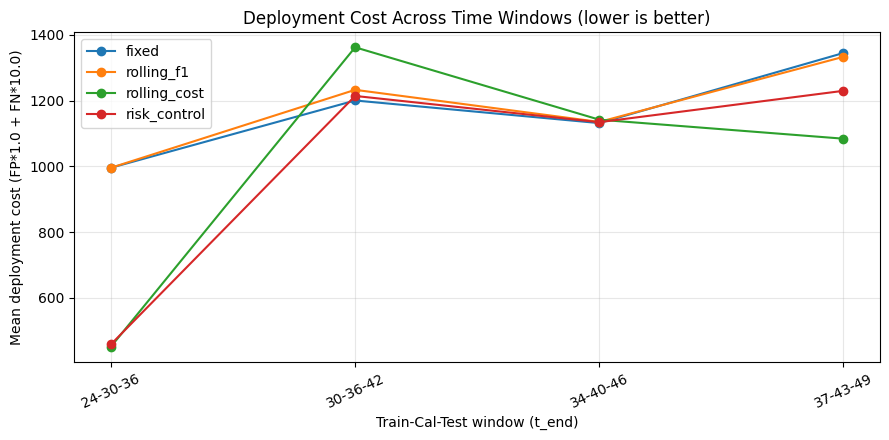

In [ ]:
# setup and config
SEEDS = [0, 1, 2, 3, 4]
WINDOWS = [
    (24, 30, 36),
    (30, 36, 42),
    (34, 40, 46),
    (37, 43, 49),
]
LAMS = [0.0, 0.15, 0.25, 0.35, 0.5, 0.7]

TOP_PCT = 1.0
PREC_TARGET = 0.90
Z = 1.96
FP_COST = 1.0
FN_COST = 10.0

# XGBoost size
N_ESTIMATORS = 6000
EARLY_STOPPING_ROUNDS = 250


# Sanity checks
if not hasattr(data, "t") or not hasattr(data, "y") or not hasattr(data, "edge_index"):
    raise ValueError("data must have attributes: t, y, edge_index")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch device:", device, "| XGBoost uses CPU tree_method='hist'", flush=True)


# Utilities

def wilson_lower_bound(k_success, n, z=1.96):
    if n <= 0:
        return 0.0
    p = k_success / n
    denom = 1 + (z**2)/n
    center = (p + (z**2)/(2*n)) / denom
    margin = (z * np.sqrt((p*(1-p)/n) + (z**2)/(4*n**2))) / denom
    return max(0.0, center - margin)

def threshold_max_f1(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    if len(thr) == 0:
        return 0.5
    f1 = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-12)
    return float(thr[int(np.argmax(f1))])

def threshold_min_cost(y_true, p, fp_cost=1.0, fn_cost=10.0):
    thr_grid = np.unique(np.quantile(p, np.linspace(0.0, 1.0, 400)))
    best_thr, best_cost = 0.5, float("inf")
    for thr in thr_grid:
        pred = (p >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        cost = fp_cost * fp + fn_cost * fn
        if cost < best_cost:
            best_cost = cost
            best_thr = float(thr)
    return best_thr

def threshold_risk_control_precision(y_true, p, prec_target=0.90, z=1.96):
    order = np.argsort(-p)
    y_sorted = y_true[order].astype(int)
    p_sorted = p[order]
    cum_tp = np.cumsum(y_sorted)
    ks = np.arange(1, len(y_sorted) + 1)

    ok = np.zeros(len(ks), dtype=bool)
    for i in range(len(ks)):
        tp = int(cum_tp[i])
        k = int(ks[i])
        lb = wilson_lower_bound(tp, k, z=z)
        ok[i] = (lb >= prec_target)

    if not ok.any():
        return 1.1
    k_best = int(np.where(ok)[0].max()) + 1
    return float(p_sorted[k_best - 1])

def topk_metrics(y_true, p, top_pct=1.0):
    n = len(p)
    k = max(1, int(np.ceil((top_pct / 100.0) * n)))
    idx = np.argsort(-p)[:k]
    y_top = y_true[idx].astype(int)
    precision = float(y_top.mean())
    recall = float(y_top.sum() / max(1, int(y_true.sum())))
    return k, precision, recall

def fit_xgb_cpu_hist(Xtr, ytr, Xcal, ycal, seed, spw):
    clf = xgb.XGBClassifier(
        n_estimators=N_ESTIMATORS,
        learning_rate=0.02,
        max_depth=6,
        min_child_weight=5,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=2.0,
        reg_alpha=0.0,
        gamma=0.0,
        objective="binary:logistic",
        eval_metric="aucpr",
        scale_pos_weight=spw,
        tree_method="hist",
        n_jobs=-1,
        random_state=seed
    )

    try:
        cb = [xgb.callback.EarlyStopping(rounds=EARLY_STOPPING_ROUNDS, save_best=True)]
        clf.fit(Xtr, ytr, eval_set=[(Xcal, ycal)], verbose=False, callbacks=cb)
    except Exception:
        clf.fit(Xtr, ytr, eval_set=[(Xcal, ycal)], verbose=False)

    return clf


# Feature builder
x_raw = getattr(data, "x_raw", data.x).float()
x_raw = torch.nan_to_num(x_raw, nan=0.0, posinf=0.0, neginf=0.0).to(device)
t_torch = data.t.to(device).long()
N = int(x_raw.size(0))

edge = data.edge_index.to(device)
src_all, dst_all = edge[0], edge[1]

# Causal edges only
keep = (t_torch[dst_all] - t_torch[src_all]) >= 0
src = src_all[keep]
dst = dst_all[keep]
dt = (t_torch[dst] - t_torch[src]).float()

t_max = float(t_torch.max().item())

def time_features(t):
    tn = (t.float() / t_max).unsqueeze(1)
    feats = [tn]
    for k in range(6):
        freq = 2.0 ** k
        feats.append(torch.sin(2 * np.pi * freq * tn))
        feats.append(torch.cos(2 * np.pi * freq * tn))
    return torch.cat(feats, dim=1)

t_enc = time_features(t_torch)

def build_features(train_mask_bool, lam, horizon_end):
    """
    Standardize using TRAIN ONLY.
    Compute features for all nodes, but only use edges with dst time <= horizon_end.
    """
    train_mask_bool = np.asarray(train_mask_bool, dtype=bool)
    tr_m = torch.tensor(train_mask_bool, device=device)

    mu = x_raw[tr_m].mean(dim=0)
    sd = x_raw[tr_m].std(dim=0).clamp(min=1e-6)
    x0 = (x_raw - mu) / sd

    # Horizon-restricted causal edges
    edge_keep = (t_torch[dst] <= horizon_end)
    src_h = src[edge_keep]
    dst_h = dst[edge_keep]
    dt_h  = dt[edge_keep]

    deg_in = torch.bincount(dst_h, minlength=N).float().to(device).unsqueeze(1)
    deg_in_log = torch.log1p(deg_in)

    w = torch.exp(-lam * dt_h)

    def agg_with_edges(x):
        out = torch.zeros((N, x.size(1)), device=device)
        out.index_add_(0, dst_h, x[src_h] * w.unsqueeze(1))
        wsum = torch.zeros((N,), device=device)
        wsum.index_add_(0, dst_h, w)
        return out / wsum.clamp(min=1e-6).unsqueeze(1), wsum.unsqueeze(1)

    h1, w1 = agg_with_edges(x0)
    h2, w2 = agg_with_edges(h1)

    X = torch.cat([
        x0,
        h1,
        h2,
        t_enc,
        deg_in_log,
        torch.log1p(w1),
        torch.log1p(w2)
    ], dim=1)

    return X.detach().cpu().numpy()


# Rolling deployment evaluation
y = data.y.detach().cpu().numpy()
t = data.t.detach().cpu().numpy()
known = (y == 0) | (y == 1)

def mask_range(lo, hi):
    return known & (t >= lo) & (t <= hi)

rows = []

total_jobs = len(SEEDS) * len(WINDOWS) * len(LAMS)
job_i = 0
global_start = time.time()

for seed in SEEDS:
    seed_start = time.time()
    np.random.seed(seed)
    torch.manual_seed(seed)

    print(f"\n=== Seed {seed} / {SEEDS[-1]} ===", flush=True)
    fixed_thr = None

    for (train_end, cal_end, test_end) in WINDOWS:
        window_start = time.time()
        print(
            f"\nWindow: train=1..{train_end} | cal={train_end+1}..{cal_end} | test={cal_end+1}..{test_end}",
            flush=True
        )

        tr_mask = mask_range(1, train_end)
        cal_mask = mask_range(train_end + 1, cal_end)
        te_mask = mask_range(cal_end + 1, test_end)

        print(
            f"  Labelled counts -> train={int(tr_mask.sum())}, cal={int(cal_mask.sum())}, test={int(te_mask.sum())}",
            flush=True
        )

        if len(np.unique(y[tr_mask])) < 2 or len(np.unique(y[cal_mask])) < 2 or len(np.unique(y[te_mask])) < 2:
            print("  Skipping window: one split has <2 classes", flush=True)
            continue

        best = None


        # Model selection on CAL horizon only
        for lam in LAMS:
            lam_start = time.time()
            job_i += 1

            print(
                f"  [{job_i}/{total_jobs}] Trying lambda={lam} on CAL horizon={cal_end}",
                flush=True
            )

            X_all_cal = build_features(tr_mask, lam=lam, horizon_end=cal_end)

            Xtr = X_all_cal[tr_mask]
            ytr = y[tr_mask]
            Xcal = X_all_cal[cal_mask]
            ycal = y[cal_mask]

            spw = float((ytr == 0).sum() / max(1, (ytr == 1).sum()))
            clf = fit_xgb_cpu_hist(Xtr, ytr, Xcal, ycal, seed=seed, spw=spw)

            pcal = clf.predict_proba(Xcal)[:, 1]
            cal_pr = float(average_precision_score(ycal, pcal))

            print(
                f"     done lambda={lam} | cal PR-AUC={cal_pr:.4f} | took {time.time() - lam_start:.1f}s",
                flush=True
            )

            if best is None or cal_pr > best["cal_pr"]:
                best = dict(lam=lam, clf=clf, cal_pr=cal_pr)

        best_lam = best["lam"]
        print(
            f"  Selected lambda={best_lam} from calibration PR-AUC={best['cal_pr']:.4f}",
            flush=True
        )


        # Rebuild with TEST horizon after lambda selection
        print(f"  Rebuilding features with TEST horizon={test_end}", flush=True)
        X_all_test = build_features(tr_mask, lam=best_lam, horizon_end=test_end)

        Xtr = X_all_test[tr_mask]
        ytr = y[tr_mask]
        Xcal = X_all_test[cal_mask]
        ycal = y[cal_mask]
        Xte = X_all_test[te_mask]
        yte = y[te_mask]

        print("  Refitting final model on chosen lambda", flush=True)
        spw = float((ytr == 0).sum() / max(1, (ytr == 1).sum()))
        clf_final = fit_xgb_cpu_hist(Xtr, ytr, Xcal, ycal, seed=seed, spw=spw)

        pcal = clf_final.predict_proba(Xcal)[:, 1]
        pte = clf_final.predict_proba(Xte)[:, 1]

        test_pr_auc = float(average_precision_score(yte, pte))
        test_roc_auc = float(roc_auc_score(yte, pte))

        thr_roll_f1 = threshold_max_f1(ycal, pcal)
        thr_roll_cost = threshold_min_cost(ycal, pcal, fp_cost=FP_COST, fn_cost=FN_COST)
        thr_risk = threshold_risk_control_precision(ycal, pcal, prec_target=PREC_TARGET, z=Z)

        if fixed_thr is None:
            fixed_thr = thr_roll_f1
        thr_fix = fixed_thr

        def eval_policy(policy_name, thr):
            pred = (pte >= thr).astype(int)
            tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()

            precision = float(precision_score(yte, pred, zero_division=0))
            recall = float(recall_score(yte, pred, zero_division=0))
            f1 = float(f1_score(yte, pred, zero_division=0))
            deploy_cost = float(FP_COST * fp + FN_COST * fn)

            k_top, p_top, r_top = topk_metrics(yte, pte, top_pct=TOP_PCT)

            return dict(
                policy=policy_name,
                threshold=float(thr),
                precision=precision,
                recall=recall,
                f1=f1,
                fp=int(fp),
                fn=int(fn),
                tp=int(tp),
                tn=int(tn),
                deploy_cost=deploy_cost,
                top_k=int(k_top),
                top_precision=float(p_top),
                top_recall=float(r_top),
            )

        for policy_name, thr in [
            ("fixed", thr_fix),
            ("rolling_f1", thr_roll_f1),
            ("rolling_cost", thr_roll_cost),
            ("risk_control", thr_risk),
        ]:
            r = eval_policy(policy_name, thr)
            rows.append({
                "seed": seed,
                "train_end": train_end,
                "cal_end": cal_end,
                "test_end": test_end,
                "best_lam": float(best_lam),
                "test_pr_auc": test_pr_auc,
                "test_roc_auc": test_roc_auc,
                **r
            })

        print(
            f"  Window done | test PR-AUC={test_pr_auc:.4f} | test ROC-AUC={test_roc_auc:.4f} | took {time.time() - window_start:.1f}s",
            flush=True
        )

    print(f"Seed {seed} done in {time.time() - seed_start:.1f}s", flush=True)

print(f"\nAll runs finished in {time.time() - global_start:.1f}s", flush=True)

df = pd.DataFrame(rows)

if len(df) == 0:
    raise ValueError("No results were produced. Check class balance in windows or earlier cells.")

print("\nSample rows:")
display(df.head(10))


# Summary tables
summary = df.groupby("policy").agg({
    "test_pr_auc": ["mean", "std"],
    "test_roc_auc": ["mean", "std"],
    "precision": ["mean", "std"],
    "recall": ["mean", "std"],
    "f1": ["mean", "std"],
    "top_precision": ["mean", "std"],
    "top_recall": ["mean", "std"],
    "deploy_cost": ["mean", "std"],
}).round(4)

print("\n==== Rolling-deployment summary (mean±std over seeds & windows) ====")
display(summary)


# Dployment cost by window figure
df["window"] = df.apply(lambda r: f"{int(r.train_end)}-{int(r.cal_end)}-{int(r.test_end)}", axis=1)

fig, ax = plt.subplots(figsize=(9, 4.5))
for policy in df["policy"].unique():
    g = df[df["policy"] == policy].groupby("window")["deploy_cost"].mean()
    ax.plot(g.index, g.values, marker="o", label=policy)

ax.set_xlabel("Train-Cal-Test window (t_end)")
ax.set_ylabel(f"Mean deployment cost (FP*{FP_COST} + FN*{FN_COST})")
ax.set_title("Deployment Cost Across Time Windows (lower is better)")
ax.legend()
ax.grid(True, alpha=0.3)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

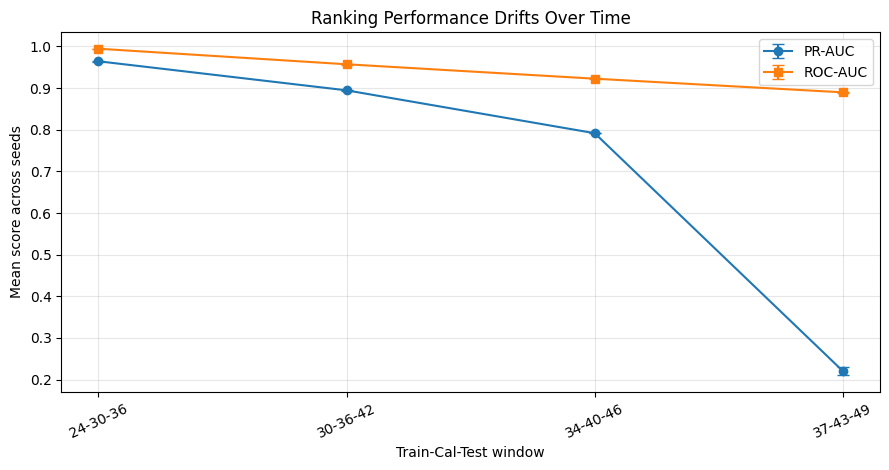

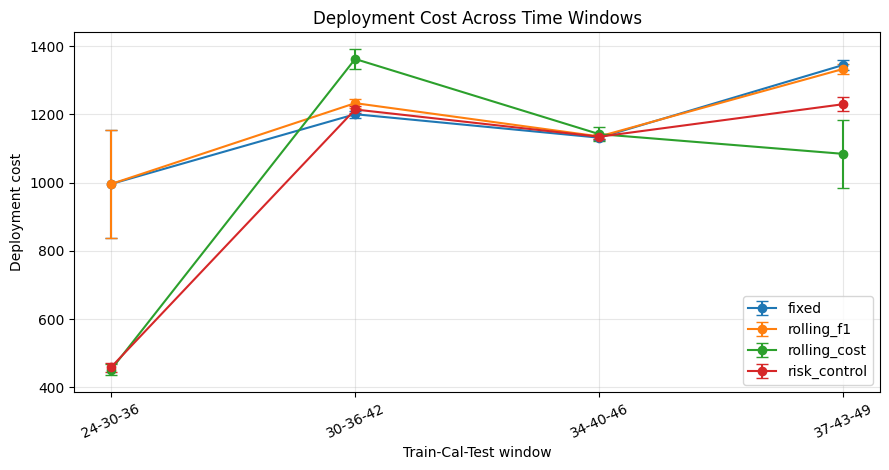


==== Policy summary (mean ± std across all seeds/windows) ====


precision          recall              f1         deploy_cost  \
                  mean     std    mean     std    mean     std        mean   
policy                                                                       
fixed           0.7460  0.2563  0.6346  0.3249  0.6725  0.3177     1168.35   
rolling_f1      0.7475  0.2825  0.6367  0.3176  0.6776  0.3102     1174.45   
rolling_cost    0.6087  0.2205  0.7328  0.2371  0.6586  0.2264     1010.25   
risk_control    0.6916  0.2571  0.6873  0.2926  0.6864  0.2708     1009.50   

                       alert_rate          alerts            
                   std       mean     std    mean       std  
policy                                                       
fixed         148.1035     0.0643  0.0414  432.25  259.3481  
rolling_f1    147.0598     0.0662  0.0443  441.65  281.6740  
rolling_cost  350.8819     0.0934  0.0505  612.95  320.8348  
risk_control  328.4327     0.0766  0.0478  504.40  291.6800

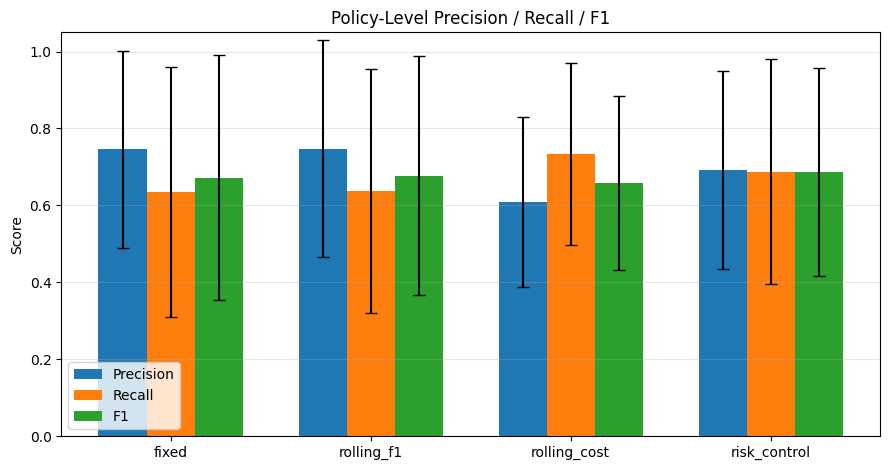

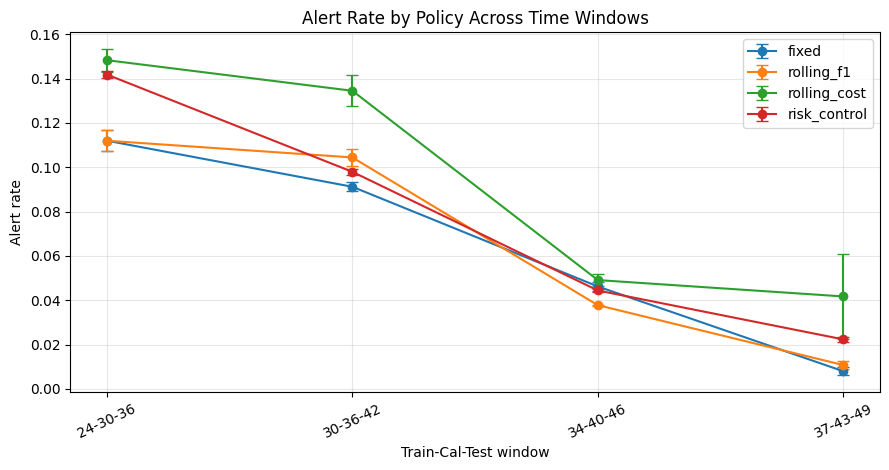


==== Deployment-cost reduction vs fixed (positive = better than fixed) ====


,mean,std
policy,,
rolling_f1_gain_vs_fixed,-6.10,20.081
rolling_cost_gain_vs_fixed,158.10,291.333
risk_control_gain_vs_fixed,158.85,241.965


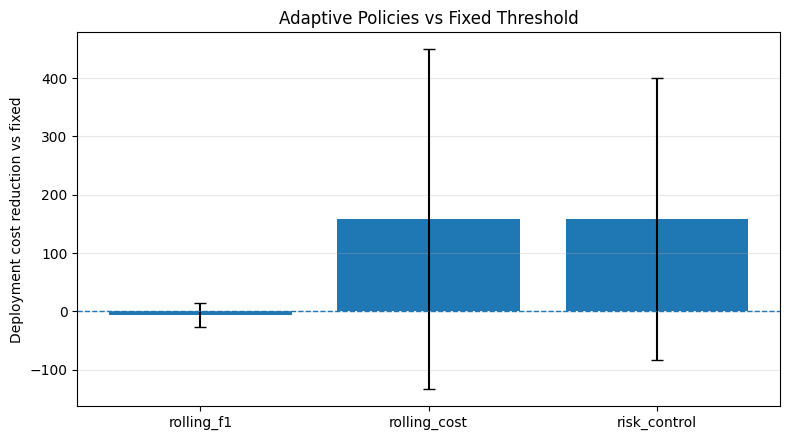


==== Window-by-window policy ablation (means) ====


,window,policy,precision,recall,f1,deploy_cost,alert_rate,alerts
0,24-30-36,fixed,0.9295,0.8689,0.8978,996.0,0.1120,676.2
1,24-30-36,risk_control,0.8097,0.9591,0.8781,459.0,0.1418,856.4
2,24-30-36,rolling_cost,0.7796,0.9649,0.8622,452.0,0.1483,895.6
3,24-30-36,rolling_f1,0.9295,0.8689,0.8978,996.0,0.1120,676.2
4,30-36-42,fixed,0.9234,0.8352,0.8770,1200.6,0.0912,632.4
5,30-36-42,risk_control,0.8641,0.8395,0.8516,1214.4,0.0980,679.2
6,30-36-42,rolling_cost,0.6407,0.8532,0.7314,1362.4,0.1345,932.8
7,30-36-42,rolling_f1,0.8144,0.8429,0.8282,1233.0,0.1044,724.2
8,34-40-46,fixed,0.8060,0.7420,0.7723,1131.8,0.0462,378.0
9,34-40-46,risk_control,0.8333,0.7380,0.7827,1134.6,0.0444,363.2



==== Compact paper table ====


precision          recall              f1         deploy_cost  \
                  mean     std    mean     std    mean     std        mean   
policy                                                                       
fixed           0.7460  0.2563  0.6346  0.3249  0.6725  0.3177     1168.35   
rolling_f1      0.7475  0.2825  0.6367  0.3176  0.6776  0.3102     1174.45   
rolling_cost    0.6087  0.2205  0.7328  0.2371  0.6586  0.2264     1010.25   
risk_control    0.6916  0.2571  0.6873  0.2926  0.6864  0.2708     1009.50   

                       alert_rate          
                   std       mean     std  
policy                                     
fixed         148.1035     0.0643  0.0414  
rolling_f1    147.0598     0.0662  0.0443  
rolling_cost  350.8819     0.0934  0.0505  
risk_control  328.4327     0.0766  0.0478


Saved:
 - paper_table_policy_summary.csv
 - paper_table_window_ablation.csv
 - paper_table_cost_gains_vs_fixed.csv


In [ ]:
if "df" not in globals():
    raise ValueError("df not found. Run the rolling evaluation cell first.")

df_plot = df.copy()

required_cols = [
    "seed", "train_end", "cal_end", "test_end",
    "policy", "test_pr_auc", "test_roc_auc",
    "precision", "recall", "f1",
    "deploy_cost", "threshold",
    "fp", "fn", "tp", "tn"
]
missing = [c for c in required_cols if c not in df_plot.columns]
if missing:
    raise ValueError(f"Missing columns in df: {missing}")

# window label
df_plot["window"] = df_plot.apply(
    lambda r: f"{int(r.train_end)}-{int(r.cal_end)}-{int(r.test_end)}", axis=1
)

# consistent window order
window_order = (
    df_plot[["train_end", "cal_end", "test_end", "window"]]
    .drop_duplicates()
    .sort_values(["train_end", "cal_end", "test_end"])
)["window"].tolist()

policy_order = ["fixed", "rolling_f1", "rolling_cost", "risk_control"]
policy_order = [p for p in policy_order if p in df_plot["policy"].unique()]


# Metrics

# total alerts
df_plot["alerts"] = df_plot["tp"] + df_plot["fp"]

# alert rate among test transactions
df_plot["test_n"] = df_plot["tp"] + df_plot["fp"] + df_plot["tn"] + df_plot["fn"]
df_plot["alert_rate"] = df_plot["alerts"] / df_plot["test_n"].clip(lower=1)

# miss rate in positives
df_plot["miss_rate"] = df_plot["fn"] / (df_plot["fn"] + df_plot["tp"]).clip(lower=1)

# specificity
df_plot["specificity"] = df_plot["tn"] / (df_plot["tn"] + df_plot["fp"]).clip(lower=1)


# Ranking drift figure
rank_df = (
    df_plot[df_plot["policy"] == policy_order[0]]
    .groupby("window")[["test_pr_auc", "test_roc_auc"]]
    .agg(["mean", "std"])
    .reindex(window_order)
)

x = np.arange(len(window_order))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.errorbar(
    x,
    rank_df[("test_pr_auc", "mean")].values,
    yerr=rank_df[("test_pr_auc", "std")].fillna(0).values,
    marker="o",
    capsize=4,
    label="PR-AUC"
)
ax.errorbar(
    x,
    rank_df[("test_roc_auc", "mean")].values,
    yerr=rank_df[("test_roc_auc", "std")].fillna(0).values,
    marker="s",
    capsize=4,
    label="ROC-AUC"
)
ax.set_xticks(x)
ax.set_xticklabels(window_order, rotation=25)
ax.set_ylabel("Mean score across seeds")
ax.set_xlabel("Train-Cal-Test window")
ax.set_title("Ranking Performance Drifts Over Time")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Deployment cost by policy over windows
cost_df = (
    df_plot.groupby(["window", "policy"])["deploy_cost"]
    .agg(["mean", "std"])
    .reset_index()
)
cost_df["window"] = pd.Categorical(cost_df["window"], categories=window_order, ordered=True)
cost_df = cost_df.sort_values(["window", "policy"])

fig, ax = plt.subplots(figsize=(9, 4.8))
for policy in policy_order:
    g = cost_df[cost_df["policy"] == policy].set_index("window").reindex(window_order)
    ax.errorbar(
        np.arange(len(window_order)),
        g["mean"].values,
        yerr=g["std"].fillna(0).values,
        marker="o",
        capsize=4,
        label=policy
    )

ax.set_xticks(np.arange(len(window_order)))
ax.set_xticklabels(window_order, rotation=25)
ax.set_xlabel("Train-Cal-Test window")
ax.set_ylabel("Deployment cost")
ax.set_title("Deployment Cost Across Time Windows")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Realised precision / recall by policy
metric_df = (
    df_plot.groupby(["policy"])[["precision", "recall", "f1", "deploy_cost", "alert_rate", "alerts"]]
    .agg(["mean", "std"])
    .round(4)
    .reindex(policy_order)
)

print("\n==== Policy summary (mean ± std across all seeds/windows) ====")
display(metric_df)

# precision/recall bar chart
pr_bar = (
    df_plot.groupby("policy")[["precision", "recall", "f1"]]
    .agg(["mean", "std"])
    .reindex(policy_order)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
bar_x = np.arange(len(policy_order))
width = 0.24

ax.bar(
    bar_x - width,
    pr_bar[("precision", "mean")].values,
    width,
    yerr=pr_bar[("precision", "std")].fillna(0).values,
    capsize=4,
    label="Precision"
)
ax.bar(
    bar_x,
    pr_bar[("recall", "mean")].values,
    width,
    yerr=pr_bar[("recall", "std")].fillna(0).values,
    capsize=4,
    label="Recall"
)
ax.bar(
    bar_x + width,
    pr_bar[("f1", "mean")].values,
    width,
    yerr=pr_bar[("f1", "std")].fillna(0).values,
    capsize=4,
    label="F1"
)

ax.set_xticks(bar_x)
ax.set_xticklabels(policy_order)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Policy-Level Precision / Recall / F1")
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Alert volume / alert rate by policy over windows
alert_df = (
    df_plot.groupby(["window", "policy"])[["alerts", "alert_rate"]]
    .agg(["mean", "std"])
    .reset_index()
)
alert_df["window"] = pd.Categorical(alert_df["window"], categories=window_order, ordered=True)
alert_df = alert_df.sort_values(["window", "policy"])

fig, ax = plt.subplots(figsize=(9, 4.8))
for policy in policy_order:
    g = alert_df[alert_df["policy"] == policy].set_index("window").reindex(window_order)
    ax.errorbar(
        np.arange(len(window_order)),
        g[("alert_rate", "mean")].values,
        yerr=g[("alert_rate", "std")].fillna(0).values,
        marker="o",
        capsize=4,
        label=policy
    )

ax.set_xticks(np.arange(len(window_order)))
ax.set_xticklabels(window_order, rotation=25)
ax.set_xlabel("Train-Cal-Test window")
ax.set_ylabel("Alert rate")
ax.set_title("Alert Rate by Policy Across Time Windows")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Pairwise cost improvement vs fixed
wide_cost = (
    df_plot.pivot_table(
        index=["seed", "window"],
        columns="policy",
        values="deploy_cost"
    )
    .reset_index()
)

if "fixed" in wide_cost.columns:
    for pol in ["rolling_f1", "rolling_cost", "risk_control"]:
        if pol in wide_cost.columns:
            wide_cost[f"{pol}_gain_vs_fixed"] = wide_cost["fixed"] - wide_cost[pol]

gain_cols = [c for c in wide_cost.columns if c.endswith("_gain_vs_fixed")]
if gain_cols:
    gain_summary = wide_cost[gain_cols].agg(["mean", "std"]).T.round(3)
    print("\n==== Deployment-cost reduction vs fixed (positive = better than fixed) ====")
    display(gain_summary)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    means = gain_summary["mean"].values
    errs = gain_summary["std"].values
    labels = [c.replace("_gain_vs_fixed", "") for c in gain_summary.index]
    ax.bar(np.arange(len(labels)), means, yerr=errs, capsize=4)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels)
    ax.set_ylabel("Deployment cost reduction vs fixed")
    ax.set_title("Adaptive Policies vs Fixed Threshold")
    ax.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


# Ablation table
ablation_window = (
    df_plot.groupby(["window", "policy"])[
        ["precision", "recall", "f1", "deploy_cost", "alert_rate", "alerts"]
    ]
    .mean()
    .round(4)
    .reset_index()
)
ablation_window["window"] = pd.Categorical(ablation_window["window"], categories=window_order, ordered=True)
ablation_window = ablation_window.sort_values(["window", "policy"])

print("\n==== Window-by-window policy ablation (means) ====")
display(ablation_window)


# Compact paper table
paper_table = (
    df_plot.groupby("policy")[["precision", "recall", "f1", "deploy_cost", "alert_rate"]]
    .agg(["mean", "std"])
    .round(4)
    .reindex(policy_order)
)

print("\n==== Compact paper table ====")
display(paper_table)


# CSV exports

paper_table.to_csv("paper_table_policy_summary.csv")
ablation_window.to_csv("paper_table_window_ablation.csv", index=False)
wide_cost.to_csv("paper_table_cost_gains_vs_fixed.csv", index=False)

print("\nSaved:")
print(" - paper_table_policy_summary.csv")
print(" - paper_table_window_ablation.csv")
print(" - paper_table_cost_gains_vs_fixed.csv")


==== Paired tests vs fixed ====


,metric,comparison,n_pairs,mean_effect,ci95_low,ci95_high,paired_t_p,wilcoxon_p,effect_definition
14,alert_rate,risk_control vs fixed,20,0.0123,0.0065,0.0180,0.0003,0.0007,positive is higher than fixed
13,alert_rate,rolling_cost vs fixed,20,0.0291,0.0204,0.0377,0.0000,0.0000,positive is higher than fixed
12,alert_rate,rolling_f1 vs fixed,20,0.0019,-0.0019,0.0057,0.3105,0.3066,positive is higher than fixed
17,cost_per_txn,risk_control vs fixed,20,0.0271,0.0084,0.0457,0.0068,0.0215,positive is improvement vs fixed
16,cost_per_txn,rolling_cost vs fixed,20,0.0286,0.0062,0.0511,0.0152,0.0696,positive is improvement vs fixed
15,cost_per_txn,rolling_f1 vs fixed,20,-0.0007,-0.0022,0.0007,0.2998,0.4216,positive is improvement vs fixed
2,deploy_cost,risk_control vs fixed,20,158.8500,45.6068,272.0932,0.0085,0.0206,positive is improvement vs fixed
1,deploy_cost,rolling_cost vs fixed,20,158.1000,21.7520,294.4480,0.0253,0.0897,positive is improvement vs fixed
0,deploy_cost,rolling_f1 vs fixed,20,-6.1000,-15.4983,3.2983,0.1902,0.2786,positive is improvement vs fixed
11,f1,risk_control vs fixed,20,0.0140,-0.0088,0.0367,0.2143,0.8408,positive is higher than fixed



==== Per-window deployment-cost gain vs fixed ====


/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2323: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/usr/local/lib/python3.12/dist-packages/scipy/stats/_distn_infrastructure.py:2324: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,window,policy,mean_cost_gain_vs_fixed,ci95_low,ci95_high,std,n
8,24-30-36,risk_control,537.0,335.950,738.050,161.920,5
4,24-30-36,rolling_cost,544.0,336.321,751.679,167.259,5
0,24-30-36,rolling_f1,0.0,NaN,NaN,0.000,5
9,30-36-42,risk_control,-13.8,-35.510,7.910,17.484,5
5,30-36-42,rolling_cost,-161.8,-203.265,-120.335,33.395,5
1,30-36-42,rolling_f1,-32.4,-56.067,-8.733,19.060,5
10,34-40-46,risk_control,-2.8,-16.098,10.498,10.710,5
6,34-40-46,rolling_cost,-10.4,-27.574,6.774,13.831,5
2,34-40-46,rolling_f1,-3.6,-15.942,8.742,9.940,5
11,37-43-49,risk_control,115.0,90.574,139.426,19.672,5


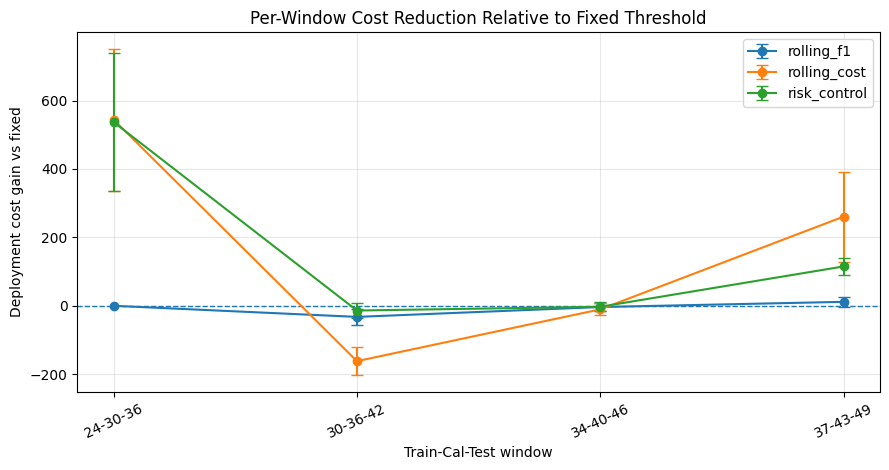


==== Workload-normalized policy table ====


precision          recall              f1         deploy_cost  \
                  mean     std    mean     std    mean     std        mean   
policy                                                                       
fixed           0.7460  0.2563  0.6346  0.3249  0.6725  0.3177     1168.35   
rolling_f1      0.7475  0.2825  0.6367  0.3176  0.6776  0.3102     1174.45   
rolling_cost    0.6087  0.2205  0.7328  0.2371  0.6586  0.2264     1010.25   
risk_control    0.6916  0.2571  0.6873  0.2926  0.6864  0.2708     1009.50   

                       alert_rate         alerts_per_1000_txns           \
                   std       mean     std                 mean      std   
policy                                                                    
fixed         148.1035     0.0643  0.0414              64.3445  41.4374   
rolling_f1    147.0598     0.0662  0.0443              66.2414  44.3445   
rolling_cost  350.8819     0.0934  0.0505              93.4158  50.5257   
risk_control  328.4327     0.0766  0.0478              76.6329  47.8409   

             cost_per_txn         cost_per_positive         cost_per_alert  \
                     mean     std              mean     std           mean   
policy                                                                       
fixed              0.1824  0.0455            3.7829  3.2974         9.9352   
rolling_f1         0.1831  0.0443            3.7767  3.2540         7.7119   
rolling_cost       0.1537  0.0540            3.2097  2.6684         2.6834   
risk_control       0.1553  0.0579            3.4056  3.1061         3.9568   

                      tp_per_100_alerts           
                  std              mean      std  
policy                                            
fixed         14.4958           74.6001  25.6308  
rolling_f1     9.9194           74.7491  28.2469  
rolling_cost   2.4832           60.8670  22.0487  
risk_control   3.9294           69.1578  25.7075


==== Per-window workload table ====


,window,policy,precision,recall,f1,deploy_cost,alert_rate,alerts_per_1000_txns,cost_per_txn,cost_per_positive,tp_per_100_alerts
0,24-30-36,fixed,0.9295,0.8689,0.8978,996.0,0.1120,111.9907,0.1650,1.3776,92.9496
1,24-30-36,risk_control,0.8097,0.9591,0.8781,459.0,0.1418,141.8350,0.0760,0.6349,80.9736
2,24-30-36,rolling_cost,0.7796,0.9649,0.8622,452.0,0.1483,148.3273,0.0749,0.6252,77.9564
3,24-30-36,rolling_f1,0.9295,0.8689,0.8978,996.0,0.1120,111.9907,0.1650,1.3776,92.9496
4,30-36-42,fixed,0.9234,0.8352,0.8770,1200.6,0.0912,91.2028,0.1731,1.7176,92.3439
5,30-36-42,risk_control,0.8641,0.8395,0.8516,1214.4,0.0980,97.9521,0.1751,1.7373,86.4107
6,30-36-42,rolling_cost,0.6407,0.8532,0.7314,1362.4,0.1345,134.5255,0.1965,1.9491,64.0650
7,30-36-42,rolling_f1,0.8144,0.8429,0.8282,1233.0,0.1044,104.4419,0.1778,1.7639,81.4377
8,34-40-46,fixed,0.8060,0.7420,0.7723,1131.8,0.0462,46.2103,0.1384,2.7605,80.5960
9,34-40-46,risk_control,0.8333,0.7380,0.7827,1134.6,0.0444,44.4010,0.1387,2.7673,83.3253



==== Camera-ready summary with 95% CIs ====


,policy,precision_mean,precision_ci95_low,precision_ci95_high,recall_mean,recall_ci95_low,recall_ci95_high,f1_mean,f1_ci95_low,f1_ci95_high,deploy_cost_mean,deploy_cost_ci95_low,deploy_cost_ci95_high,alert_rate_mean,alert_rate_ci95_low,alert_rate_ci95_high,cost_per_txn_mean,cost_per_txn_ci95_low,cost_per_txn_ci95_high
0,fixed,0.7460,0.6260,0.8660,0.6346,0.4825,0.7867,0.6725,0.5238,0.8212,1168.35,1099.0354,1237.6646,0.0643,0.0450,0.0837,0.1824,0.1611,0.2036
1,rolling_f1,0.7475,0.6153,0.8797,0.6367,0.4880,0.7853,0.6776,0.5324,0.8228,1174.45,1105.6239,1243.2761,0.0662,0.0455,0.0870,0.1831,0.1624,0.2038
2,rolling_cost,0.6087,0.5055,0.7119,0.7328,0.6218,0.8438,0.6586,0.5526,0.7645,1010.25,846.0322,1174.4678,0.0934,0.0698,0.1171,0.1537,0.1285,0.1790
3,risk_control,0.6916,0.5713,0.8119,0.6873,0.5503,0.8242,0.6864,0.5597,0.8132,1009.50,855.7888,1163.2112,0.0766,0.0542,0.0990,0.1553,0.1282,0.1824



Saved:
 - paper_stats_paired_tests.csv
 - paper_stats_window_cost_gains.csv
 - paper_stats_workload_policy_table.csv
 - paper_stats_workload_window_table.csv
 - paper_stats_camera_ready_summary.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


if "df" not in globals():
    raise ValueError("df not found. Run the rolling evaluation cell first.")

dd = df.copy()

required_cols = [
    "seed", "train_end", "cal_end", "test_end", "policy",
    "precision", "recall", "f1", "deploy_cost",
    "tp", "fp", "tn", "fn"
]
missing = [c for c in required_cols if c not in dd.columns]
if missing:
    raise ValueError(f"Missing columns in df: {missing}")

dd["window"] = dd.apply(
    lambda r: f"{int(r.train_end)}-{int(r.cal_end)}-{int(r.test_end)}", axis=1
)

policy_order = ["fixed", "rolling_f1", "rolling_cost", "risk_control"]
policy_order = [p for p in policy_order if p in dd["policy"].unique()]


# Workload metrics
dd["alerts"] = dd["tp"] + dd["fp"]
dd["test_n"] = dd["tp"] + dd["fp"] + dd["tn"] + dd["fn"]
dd["positives"] = dd["tp"] + dd["fn"]

dd["alert_rate"] = dd["alerts"] / dd["test_n"].clip(lower=1)
dd["miss_rate"] = dd["fn"] / dd["positives"].clip(lower=1)
dd["specificity"] = dd["tn"] / (dd["tn"] + dd["fp"]).clip(lower=1)

# Operational metrics
dd["cost_per_txn"] = dd["deploy_cost"] / dd["test_n"].clip(lower=1)
dd["cost_per_positive"] = dd["deploy_cost"] / dd["positives"].clip(lower=1)
dd["cost_per_alert"] = dd["deploy_cost"] / dd["alerts"].clip(lower=1)

# detections per 100 alerts
dd["tp_per_100_alerts"] = 100.0 * dd["tp"] / dd["alerts"].clip(lower=1)

# alerts per 1000 txns
dd["alerts_per_1000_txns"] = 1000.0 * dd["alerts"] / dd["test_n"].clip(lower=1)


# mean ± CI
def mean_ci95(x):
    x = np.asarray(x, dtype=float)
    n = len(x)
    mean = float(np.mean(x))
    if n <= 1:
        return mean, np.nan, np.nan
    se = stats.sem(x, nan_policy="omit")
    lo, hi = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
    return mean, float(lo), float(hi)


# Paired tests vs fixed
wide = dd.pivot_table(
    index=["seed", "window"],
    columns="policy",
    values=[
        "deploy_cost", "precision", "recall", "f1",
        "alert_rate", "alerts_per_1000_txns", "cost_per_txn"
    ]
)

tests = []

comparisons = ["rolling_f1", "rolling_cost", "risk_control"]
metrics = ["deploy_cost", "precision", "recall", "f1", "alert_rate", "cost_per_txn"]

for metric in metrics:
    if (metric, "fixed") not in wide.columns:
        continue

    base = wide[(metric, "fixed")]

    for pol in comparisons:
        if (metric, pol) not in wide.columns:
            continue

        other = wide[(metric, pol)]
        pair = pd.concat([base, other], axis=1).dropna()
        if len(pair) < 2:
            continue

        x = pair.iloc[:, 0].values
        y = pair.iloc[:, 1].values
        diff = x - y if metric in ["deploy_cost", "cost_per_txn"] else y - x

        # t-test
        t_stat, t_p = stats.ttest_rel(y, x, nan_policy="omit")

        # wilcoxon
        try:
            w_stat, w_p = stats.wilcoxon(y, x)
        except Exception:
            w_stat, w_p = np.nan, np.nan

        mean_diff, lo, hi = mean_ci95(diff)

        tests.append({
            "metric": metric,
            "comparison": f"{pol} vs fixed",
            "n_pairs": len(pair),
            "mean_effect": mean_diff,
            "ci95_low": lo,
            "ci95_high": hi,
            "paired_t_p": t_p,
            "wilcoxon_p": w_p,
            "effect_definition":
                "positive is improvement vs fixed"
                if metric in ["deploy_cost", "cost_per_txn"]
                else "positive is higher than fixed"
        })

tests_df = pd.DataFrame(tests).sort_values(["metric", "comparison"])
print("\n==== Paired tests vs fixed ====")
display(tests_df.round(4))


# Cost gain vs fixed per window
cost_wide = dd.pivot_table(
    index=["seed", "window"],
    columns="policy",
    values="deploy_cost"
).reset_index()

gain_rows = []
for pol in comparisons:
    if "fixed" not in cost_wide.columns or pol not in cost_wide.columns:
        continue

    tmp = cost_wide[["seed", "window", "fixed", pol]].dropna().copy()
    tmp["gain_vs_fixed"] = tmp["fixed"] - tmp[pol]

    by_window = tmp.groupby("window")["gain_vs_fixed"]
    for window, vals in by_window:
        vals = vals.values
        mean, lo, hi = mean_ci95(vals)
        gain_rows.append({
            "window": window,
            "policy": pol,
            "mean_cost_gain_vs_fixed": mean,
            "ci95_low": lo,
            "ci95_high": hi,
            "std": float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan,
            "n": len(vals)
        })

gain_window_df = pd.DataFrame(gain_rows)
window_order = (
    dd[["train_end", "cal_end", "test_end", "window"]]
    .drop_duplicates()
    .sort_values(["train_end", "cal_end", "test_end"])
)["window"].tolist()

gain_window_df["window"] = pd.Categorical(gain_window_df["window"], categories=window_order, ordered=True)
gain_window_df = gain_window_df.sort_values(["window", "policy"])

print("\n==== Per-window deployment-cost gain vs fixed ====")
display(gain_window_df.round(3))

# Per-window gains plotted
fig, ax = plt.subplots(figsize=(9, 4.8))
for pol in comparisons:
    g = gain_window_df[gain_window_df["policy"] == pol].set_index("window").reindex(window_order)
    if len(g) == 0:
        continue
    ax.errorbar(
        np.arange(len(window_order)),
        g["mean_cost_gain_vs_fixed"].values,
        yerr=np.vstack([
            g["mean_cost_gain_vs_fixed"].values - g["ci95_low"].values,
            g["ci95_high"].values - g["mean_cost_gain_vs_fixed"].values
        ]),
        marker="o",
        capsize=4,
        label=pol
    )

ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xticks(np.arange(len(window_order)))
ax.set_xticklabels(window_order, rotation=25)
ax.set_xlabel("Train-Cal-Test window")
ax.set_ylabel("Deployment cost gain vs fixed")
ax.set_title("Per-Window Cost Reduction Relative to Fixed Threshold")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


# Policy workload table
workload_table = (
    dd.groupby("policy")[
        [
            "precision", "recall", "f1", "deploy_cost",
            "alert_rate", "alerts_per_1000_txns",
            "cost_per_txn", "cost_per_positive",
            "cost_per_alert", "tp_per_100_alerts"
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
    .reindex(policy_order)
)

print("\n==== Workload-normalized policy table ====")
display(workload_table)


# Workload table per-window
workload_window = (
    dd.groupby(["window", "policy"])[
        [
            "precision", "recall", "f1", "deploy_cost",
            "alert_rate", "alerts_per_1000_txns",
            "cost_per_txn", "cost_per_positive", "tp_per_100_alerts"
        ]
    ]
    .mean()
    .round(4)
    .reset_index()
)

workload_window["window"] = pd.Categorical(workload_window["window"], categories=window_order, ordered=True)
workload_window = workload_window.sort_values(["window", "policy"])

print("\n==== Per-window workload table ====")
display(workload_window)


# Camera-ready table
camera_ready = []
for pol in policy_order:
    sub = dd[dd["policy"] == pol]
    row = {"policy": pol}
    for metric in ["precision", "recall", "f1", "deploy_cost", "alert_rate", "cost_per_txn"]:
        mean, lo, hi = mean_ci95(sub[metric].values)
        row[f"{metric}_mean"] = round(mean, 4)
        row[f"{metric}_ci95_low"] = round(lo, 4) if pd.notna(lo) else np.nan
        row[f"{metric}_ci95_high"] = round(hi, 4) if pd.notna(hi) else np.nan
    camera_ready.append(row)

camera_ready_df = pd.DataFrame(camera_ready)
print("\n==== Camera-ready summary with 95% CIs ====")
display(camera_ready_df)


# Save
tests_df.to_csv("paper_stats_paired_tests.csv", index=False)
gain_window_df.to_csv("paper_stats_window_cost_gains.csv", index=False)
workload_table.to_csv("paper_stats_workload_policy_table.csv")
workload_window.to_csv("paper_stats_workload_window_table.csv", index=False)
camera_ready_df.to_csv("paper_stats_camera_ready_summary.csv", index=False)

print("\nSaved:")
print(" - paper_stats_paired_tests.csv")
print(" - paper_stats_window_cost_gains.csv")
print(" - paper_stats_workload_policy_table.csv")
print(" - paper_stats_workload_window_table.csv")
print(" - paper_stats_camera_ready_summary.csv")